## Sobre o projeto 
Uma empresa de consultoria que atua em Big Data e Data Science deseja contratar 
Cientistas de Dados entre pessoas que obtenham aprovação em alguns cursos ministrados pela 
empresa. 
Muitas pessoas se inscrevem para o treinamento. A empresa quer saber quais desses 
candidatos realmente querem trabalhar para a empresa após o treinamento ou estão apenas 
fazendo o treinamento para retornarem ao mercado à procura de um novo emprego. O objetivo 
é contratar os profissionais com perfil adequado, a fim de reduzir o custo e o tempo de 
contratação, bem como a qualidade do treinamento ou planejamento dos cursos e categorização 
dos candidatos. 
Informações relacionadas a dados demográficos, educação e experiência estão 
disponíveis no conjunto de dados fornecido.
Nosso objetivo será realizar um extenso trabalho de análise nos dados, compreender 
como estão organizados, realizar limpeza e transformação dos dados conforme necessário, 
detectar eventuais padrões e diagnósticos e ao final emitir um parecer com um resumo sobre os 
dados.


## Fonte de dados:
Usei como fonte de dados o dataset disponível para download no link abaixo.
https://www.kaggle.com/arashnic/hr-analytics-job-change-of-data-scientists

Este conjunto de dados foi desenvolvido para estudar quais características dos candidatos estão
associadas à intenção de buscar um novo emprego. O objetivo do dataset é exatamente fazer pesquisas de RH.

**Atenção ao significado da variável alvo:** `target = 1` indica que o candidato **declarou estar buscando
uma mudança de emprego** no momento do treinamento. Não é um registro de desligamento efetivo (turnover).
Por isso, ao longo do notebook falo em *intenção de mudança*, e não em saída da empresa.

Os dados são observacionais: a análise mostra **associações** entre o perfil do candidato e a intenção
declarada, e não permite afirmar que uma característica *causa* a intenção de mudar.

## Instalando e carregando pacotes

In [1]:
# Versão da Linguagem Python
from platform import python_version
print('Versão da Linguagem Python Usada Neste Jupyter Notebook:', python_version())

Versão da Linguagem Python Usada Neste Jupyter Notebook: 3.12.7


In [2]:
# Instala o pacote watermark. 
# Esse pacote é usado para gravar as versões de outros pacotes usados neste jupyter notebook.
!pip install -q -U watermark

In [3]:
# Para criar um mapa com os valores ausentes 
!pip install -q missingno

In [4]:
# Pacote que permite categorizar as variáveis
!pip install -q category_encoders

In [5]:
# Pacote para criação de gráficos 
!pip install -q plotly

In [6]:
# Imports

# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import missingno

# Estatística
import scipy
from scipy.stats import normaltest
from scipy.stats import chi2_contingency

# Engenharia de Atributos
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
import category_encoders as ce

# Ignore Warning
import sys
import warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")

## Carregando dados

In [7]:
##carregando dataset
df = pd.read_csv("dataset/raw/aug_train.csv")

In [8]:
#shape para saber se faltou alguma coisa do original
df.shape

(19158, 14)

In [9]:
#colunas do df 
df.columns

Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='object')

In [10]:
#amostra dos dados 
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [11]:
#informaçães dos dados(saber quais os tipos dos dados)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

## Análise Exploratória de Dados

In [12]:
# Descrevendo os dados não numéricos
df.describe(include = object)

,city,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job
count,19158,14650,19158,18772,18698,16345,19093,13220,13018,18735
unique,123,3,2,3,5,6,22,8,6,6
top,city_103,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,1
freq,4355,13221,13792,13817,11598,14492,3286,3083,9817,8040


In [13]:
# Descrevendo os dados numéricos, embora enrollee_id e target sejam numéricos , elas não serão necessária para o resumo estatístico( id é 
# só para identificação e target está como categorica), vou dropar essas colunas 
df.describe().drop(columns = ['enrollee_id', 'target'])

,city_development_index,training_hours
count,19158.000000,19158.000000
mean,0.828848,65.366896
std,0.123362,60.058462
min,0.448000,1.000000
25%,0.740000,23.000000
50%,0.903000,47.000000
75%,0.920000,88.000000
max,0.949000,336.000000


* Em **city_development_index** (CDI), os valores médios são 0,828, mediana 0,903 e std 0,123. Isso significa que a maioria dos candidatos é de cidades bem desenvolvidas.


* Em **training_hours**, os valores médios são 65,367, mediana 47 e max 336. Isso significa que há mais candidatos com poucas horas de treinamento, mas alguns candidatos gastam muito tempo para fazer o treinamento.

### Visualizando as Variáveis Categóricas

In [14]:
# como vou visualizar os dados das variáveis categóricas, vou transformar em uma lista e gerar um loop para percorrer essa lista e gerar
# gráficos de todas as colunas listadas

list(df.columns.values)[3:12]

['gender',
 'relevent_experience',
 'enrolled_university',
 'education_level',
 'major_discipline',
 'experience',
 'company_size',
 'company_type',
 'last_new_job']

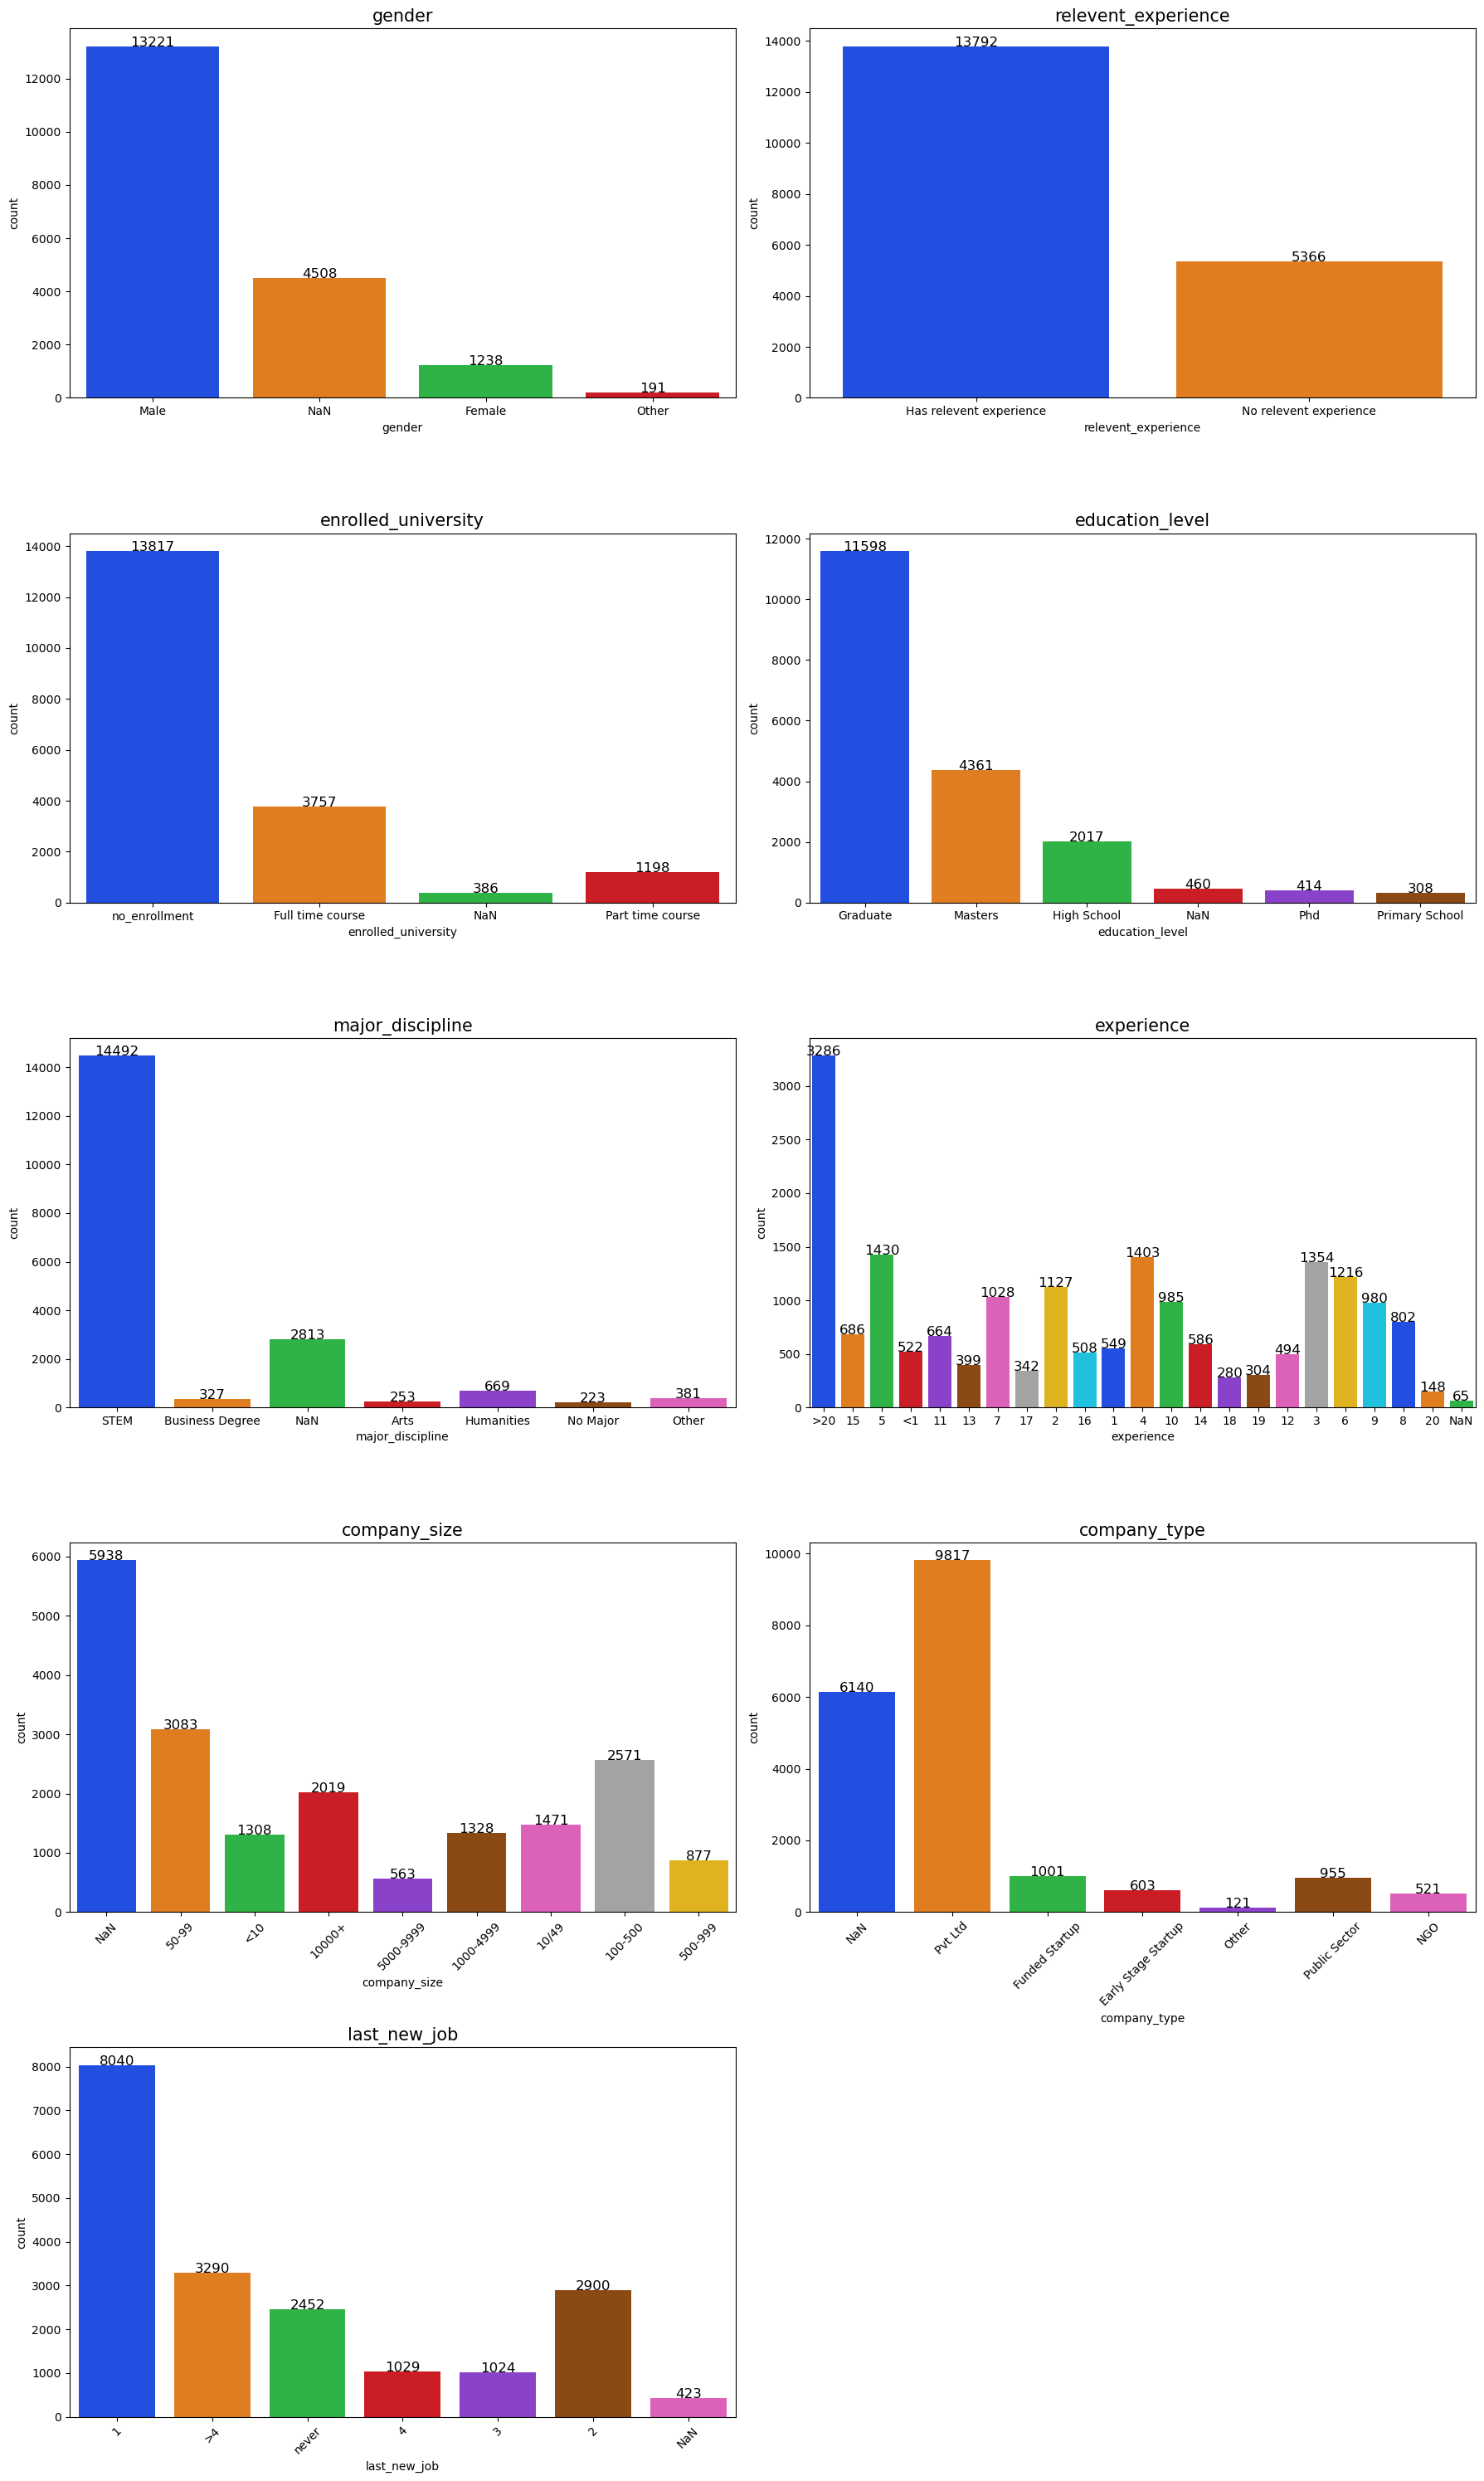

In [15]:
#agora temos uma lista com as colunas de variáveis categóricas, vou criar um plot e um loop para criar um gráfico de cada coluna
# e saber se tem algum dado ausente 
# Plot
plt.figure(figsize = (18,30))

#lista de colunas
column_list = list(df.columns.values)[3:12]

# contador
A = 0

#Criando o loop para percorrer a lista 
for i in column_list:
    A += 1
    plt.subplot(5, 2, A)
    
    
    ax = sns.countplot(data = df.fillna('NaN'), x = i, hue = i, palette = 'bright', legend = False)
    
    plt.title(i, fontsize = 15)
    
    for p in ax.patches:
        # O if p.get_height() > 0 evita erros com valores nulos/vazios
        if p.get_height() > 0:
            ax.annotate(f'\n{int(p.get_height())}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha = 'center', va = 'baseline', color = 'black', size = 12)
    
    if A >= 7:
        plt.xticks(rotation = 45)

# Layout
plt.tight_layout(h_pad = 2)

### Verificando a Distribuição das Variáveis Numéricas

In [16]:
# destacando as colunas as serem usadas 
df.describe().drop(columns = ['enrollee_id', 'target'])

,city_development_index,training_hours
count,19158.000000,19158.000000
mean,0.828848,65.366896
std,0.123362,60.058462
min,0.448000,1.000000
25%,0.740000,23.000000
50%,0.903000,47.000000
75%,0.920000,88.000000
max,0.949000,336.000000


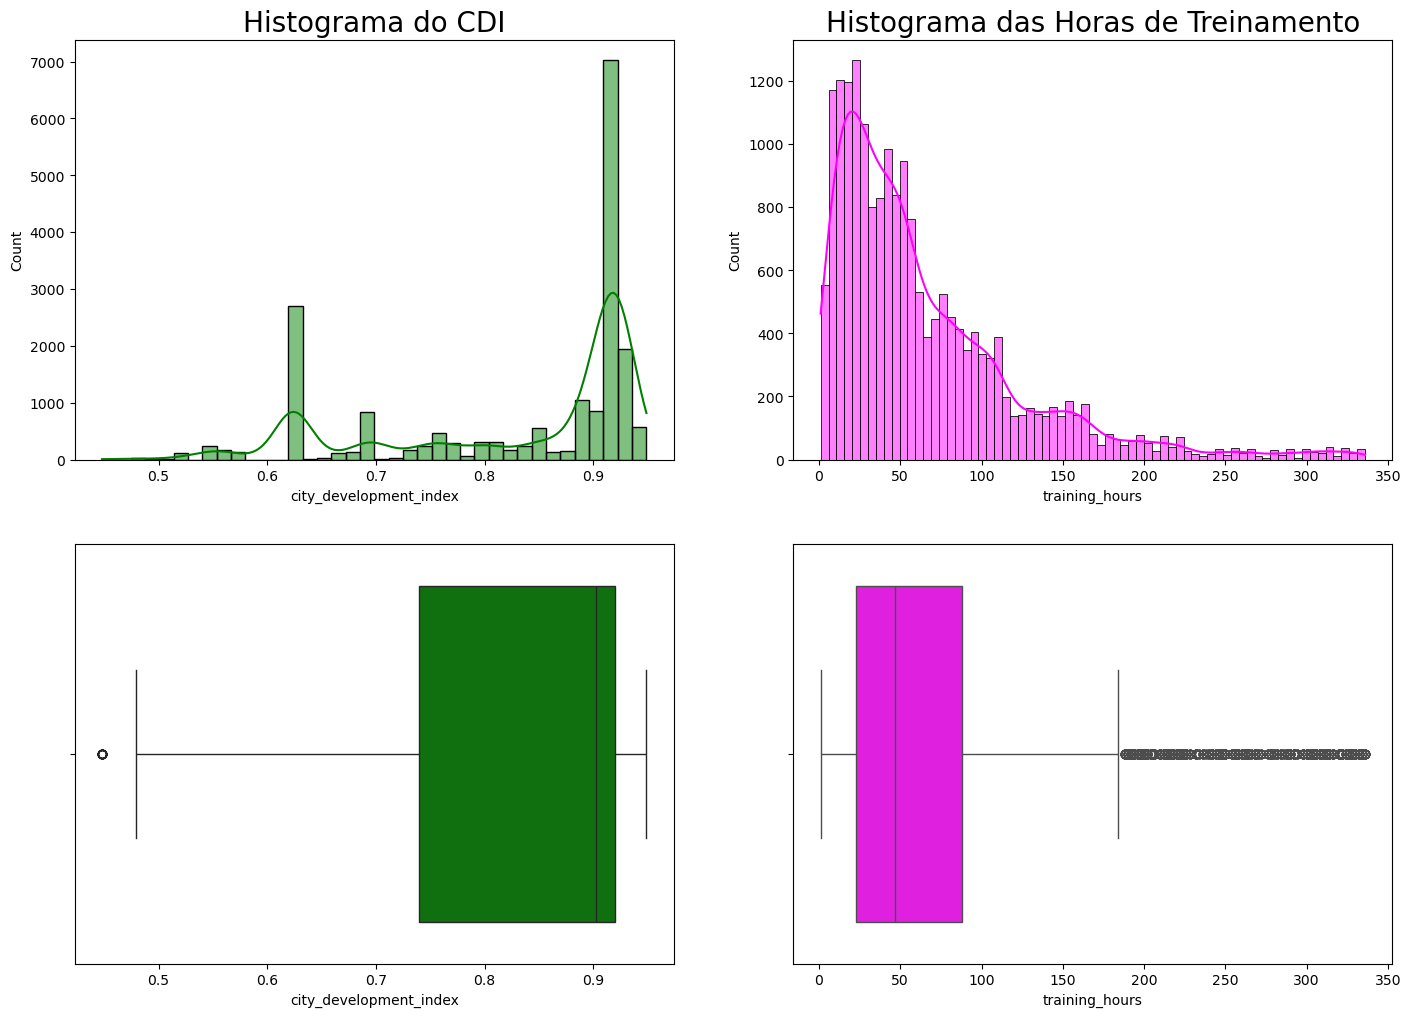

In [17]:
# seguindo com a plotagem
plt.figure(figsize = (17,12))
# Subplots com histogramas
plt.subplot(221)
sns.color_palette("hls", 8)
sns.histplot(df['city_development_index'], kde = True, color = "green")
plt.title('Histograma do CDI', fontsize = 20)

plt.subplot(222)
sns.histplot(df['training_hours'], kde = True, color = "magenta")
plt.title('Histograma das Horas de Treinamento', fontsize = 20)

# Subplots com boxplots
plt.subplot(223)
sns.boxplot(x = df['city_development_index'], color = "green")

plt.subplot(224)
sns.boxplot(x = df['training_hours'], color = "magenta")

plt.show()

Como ficou claro no gráfico acima essa amostra não tem normal uma distribuição normal, no boxplot pode se observar a presença de outliers em ambos os gráficos, mesmo sabendo que não é uma distribuição normal vou fazer um teste de normalidade 

In [18]:
# Teste de Normalidade da Distribuição

# Lista com as variáveis numéricas
numerical_feature = ['city_development_index', 'training_hours']

# Loop
for i in numerical_feature:
    
    # Calcula a normalidade
    stats, pval = normaltest(df[i])
    
     # Checar valor-p
    if pval > 0.05:
        print(i, ': Distribuição Normal')
    else:
        print(i, ': Distribuição Não Normal')

city_development_index : Distribuição Não Normal
training_hours : Distribuição Não Normal



* As variáveis **city_development_index** e **training_hours** não seguem a distribuição normal. Para a análise numérica, usaremos o método não paramétrico.


* Dados de **training_hours** estão localizados principalmente no lado esquerdo do histograma. É um comportamento esperado porque as pessoas geralmente ficam animadas ao fazer o treinamento no início, mas nem todos que começam conseguem terminar uma maratona. ;-)

  Como as variáveis não seguem o padrão normal, para a análise numérica usaremos o método não paramétrico.

### Correlação dos Dados

#### Correlação de Spearman Entre Variáveis Numéricas

Analisamos a correlação entre as variáveis numéricas e entre as variáveis numéricas e a variável alvo (o que estamos querendo analisar).

In [19]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [20]:
df.columns

Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='object')

In [21]:
#criando uma cópia do df original pois vou mudar o type de algumas variáveis e não quero alterar o df original
df_numerical = df.copy()

In [22]:
df_numerical["experience"].value_counts()

experience
>20    3286
5      1430
4      1403
3      1354
6      1216
2      1127
7      1028
10      985
9       980
8       802
15      686
11      664
14      586
1       549
<1      522
16      508
12      494
13      399
17      342
19      304
18      280
20      148
Name: count, dtype: int64

In [23]:
# Convertemos a variável experience para numérica
df_numerical["experience"] = np.where(df_numerical["experience"] == "<1", 1, df_numerical["experience"])
df_numerical["experience"] = np.where(df_numerical["experience"] == ">20", 21, df_numerical["experience"])
df_numerical["experience"] = df_numerical["experience"].astype(float)

In [24]:
df_numerical["experience"].value_counts()

experience
21.0    3286
5.0     1430
4.0     1403
3.0     1354
6.0     1216
2.0     1127
1.0     1071
7.0     1028
10.0     985
9.0      980
8.0      802
15.0     686
11.0     664
14.0     586
16.0     508
12.0     494
13.0     399
17.0     342
19.0     304
18.0     280
20.0     148
Name: count, dtype: int64

In [25]:
df_numerical["last_new_job"].value_counts()

last_new_job
1        8040
>4       3290
2        2900
never    2452
4        1029
3        1024
Name: count, dtype: int64

In [26]:
# Convertendo tb a variável last_new_job para numérica
df_numerical["last_new_job"] = np.where(df_numerical["last_new_job"] == "never", 0, df_numerical["last_new_job"])
df_numerical["last_new_job"] = np.where(df_numerical["last_new_job"] == ">4", 5, df_numerical["last_new_job"])
df_numerical["last_new_job"] = df_numerical["last_new_job"].astype(float)

In [27]:
df_numerical["last_new_job"].value_counts()

last_new_job
1.0    8040
5.0    3290
2.0    2900
0.0    2452
4.0    1029
3.0    1024
Name: count, dtype: int64

In [28]:
df_numerical.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,21.0,NaN,NaN,1.0,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,5.0,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,0.0,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,1.0,NaN,Pvt Ltd,0.0,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,21.0,50-99,Funded Startup,4.0,8,0.0


In [29]:
df_numerical.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  float64
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  float64
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(4), int64(2), object(8)
mem

In [30]:
# Adicionando o parâmetro que força o Pandas a olhar só para números
df_numerical.drop("enrollee_id", axis=1).corr(method="spearman", numeric_only=True)

,city_development_index,experience,last_new_job,training_hours,target
city_development_index,1.000000,0.300997,0.182698,0.007491,-0.279165
experience,0.300997,1.000000,0.473284,0.003569,-0.183721
last_new_job,0.182698,0.473284,1.000000,0.002959,-0.082045
training_hours,0.007491,0.003569,0.002959,1.000000,-0.014126
target,-0.279165,-0.183721,-0.082045,-0.014126,1.000000


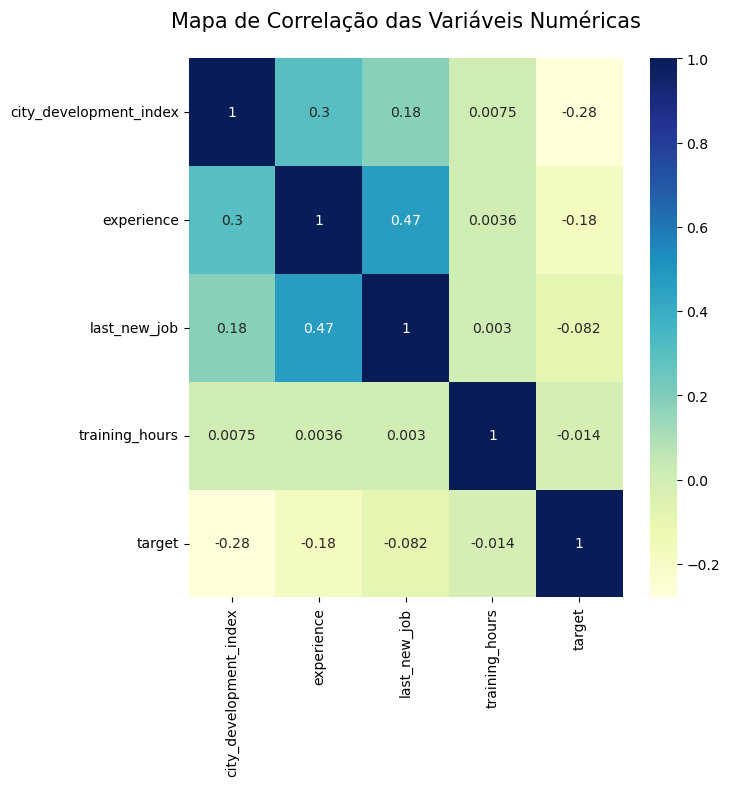

In [31]:
# fazendo a correlação 
# Heatmap
plt.figure(figsize = (7,7))
sns.heatmap(df_numerical.drop("enrollee_id", axis = 1).corr(method="spearman", numeric_only=True), annot = True, cmap = "YlGnBu")
plt.title("Mapa de Correlação das Variáveis Numéricas\n", fontsize = 15)
plt.show()

Pela correlação de spearman, last_new_job e experience têm correlação média (0,473), enquanto outros têm correlação fraca.

As variáveis last_new_job e training_hours tem correlação próxima de zero com a variável alvo e poderiam ser descartadas.

Para a relação entre as variáveis categóricas e a variável alvo, usaremos WOE e IV.

### Weight of Evidence (WOE) e Information Value (IV)

Este conjunto de dados contém mais dados com tipo categórico do que tipo numérico. Usaremos recursos categóricos nominais para WOE e IV.

Interpretamos o resultado de IV assim:

Information Value, Poder de Previsão

< 0.02, não deve ser usado para previsão

0.02 - 0.1, preditor fraco

0.1 - 0.3, preditor médio

0.3 - 0.5, preditor forte
    
> 0.5, parece bom demais para ser verdade

In [32]:
# Loop  dropando as colunas numéricas e as que não fazem sentido usar na análise,
# criando um loop da variável alvo (target) com as demais variáveis 
for i in df.drop(columns = ['target',
                            'enrollee_id',
                            'city',
                            'city_development_index',
                            'training_hours',
                            'experience',
                            'last_new_job',
                            'company_size']).columns:
    
    df_woe_iv = (pd.crosstab(df[i], df['target'], normalize = 'columns')
                 .assign(woe = lambda dfx: np.log(dfx[1] / dfx[0]))
                 .assign(iv = lambda dfx: np.sum(dfx['woe'] * (dfx[1]-dfx[0]))))
    
    print(df_woe_iv,'\n------------------------------------------------------------')

target      0.0       1.0       woe        iv
gender                                       
Female  0.08098  0.096222  0.172452  0.003337
Male    0.90650  0.889020 -0.019471  0.003337
Other   0.01252  0.014758  0.164458  0.003337 
------------------------------------------------------------
target                        0.0       1.0       woe        iv
relevent_experience                                            
Has relevent experience  0.753147  0.619845 -0.194790  0.083523
No relevent experience   0.246853  0.380155  0.431784  0.083523 
------------------------------------------------------------
target                    0.0       1.0       woe        iv
enrolled_university                                        
Full time course     0.164754  0.307477  0.623947  0.118886
Part time course     0.063465  0.064890  0.022210  0.118886
no_enrollment        0.771781  0.627632 -0.206746  0.118886 
------------------------------------------------------------
target                0.0   

<Figure size 1000x1200 with 0 Axes>

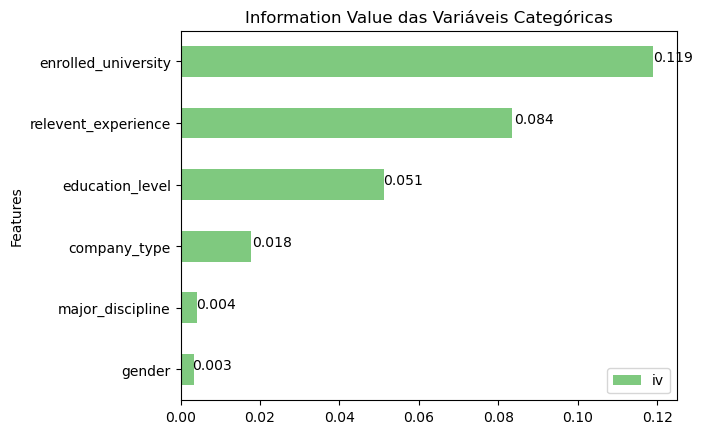

In [33]:
# Plot do Information Value

# Variáveis categóricas
columns_cat = df.drop(columns = ['target',
                                 'enrollee_id',
                                 'city',
                                 'city_development_index',
                                 'training_hours',
                                 'experience',
                                 'last_new_job',
                                 'company_size']).columns

# Lista para o IV
iv = []

# Loop
for i in columns_cat:
    df_woe_iv = (pd.crosstab(df[i], df['target'], normalize = 'columns')
                 .assign(woe = lambda dfx: np.log(dfx[1] / dfx[0]))
                 .assign(iv = lambda dfx: np.sum(dfx['woe']*(dfx[1]-dfx[0]))))
    iv.append(df_woe_iv['iv'][0])

# Dataframe
df_iv = pd.DataFrame({'Features':columns_cat,'iv':iv}).set_index('Features').sort_values(by = 'iv')

# Plot
# Figura
plt.figure(figsize = (10,12))
df_iv.plot(kind = 'barh', title = 'Information Value das Variáveis Categóricas', colormap = "Accent")
for index, value in enumerate(list(round(df_iv["iv"],3))):
    plt.text((value), index, str(value))
plt.legend(loc  = "lower right")
plt.show()

* No gráfico acima, podemos ver a ordem dos recursos com base em seu poder preditivo em relação ao alvo.
* Com base em seu valor IV, `enrolled_university` é um preditor médio, `relevent_experience` e `education_level` são preditores fracos e os outros são inúteis para a previsão.

### Identificando Valores Ausentes

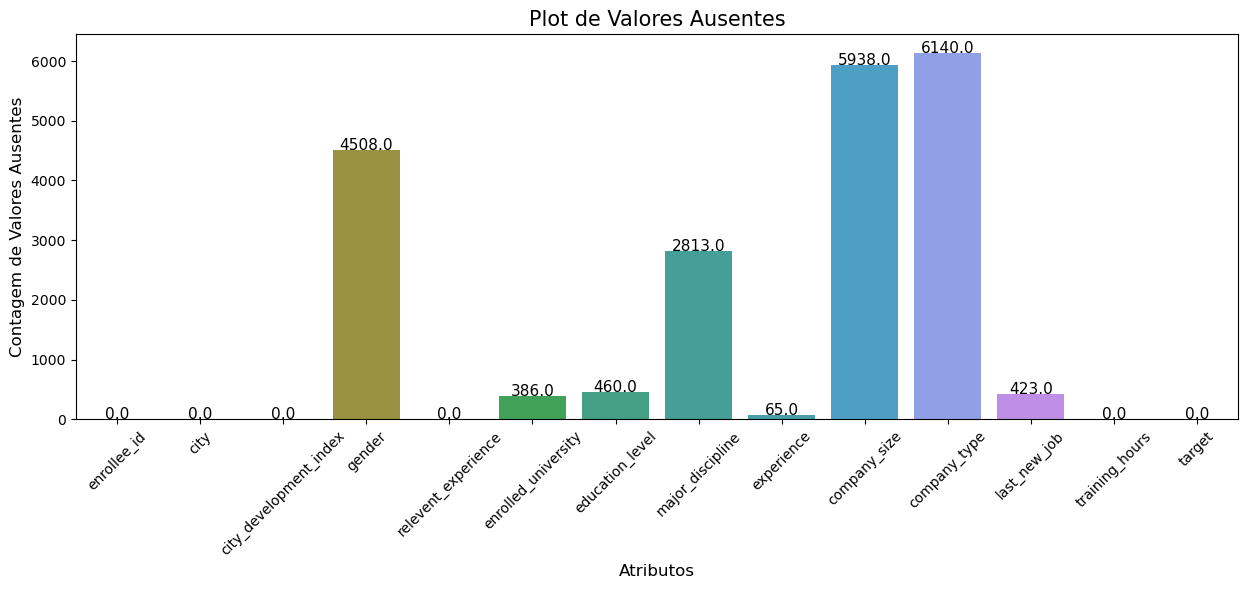

In [34]:
# Valores ausentes por coluna
null_df = df.isna().sum().reset_index()

# Figura
ax = plt.figure(figsize = (15,5))

# Barplot
ax = sns.barplot(x=null_df['index'], y=null_df[0], palette='husl')
plt.xlabel('Atributos', fontsize = 12)
plt.ylabel('Contagem de Valores Ausentes', fontsize = 12)
plt.xticks(rotation = 45)
plt.title("Plot de Valores Ausentes", fontsize = 15)

for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, (p.get_height())), ha = 'center', color = 'black', size = 11)

plt.show()

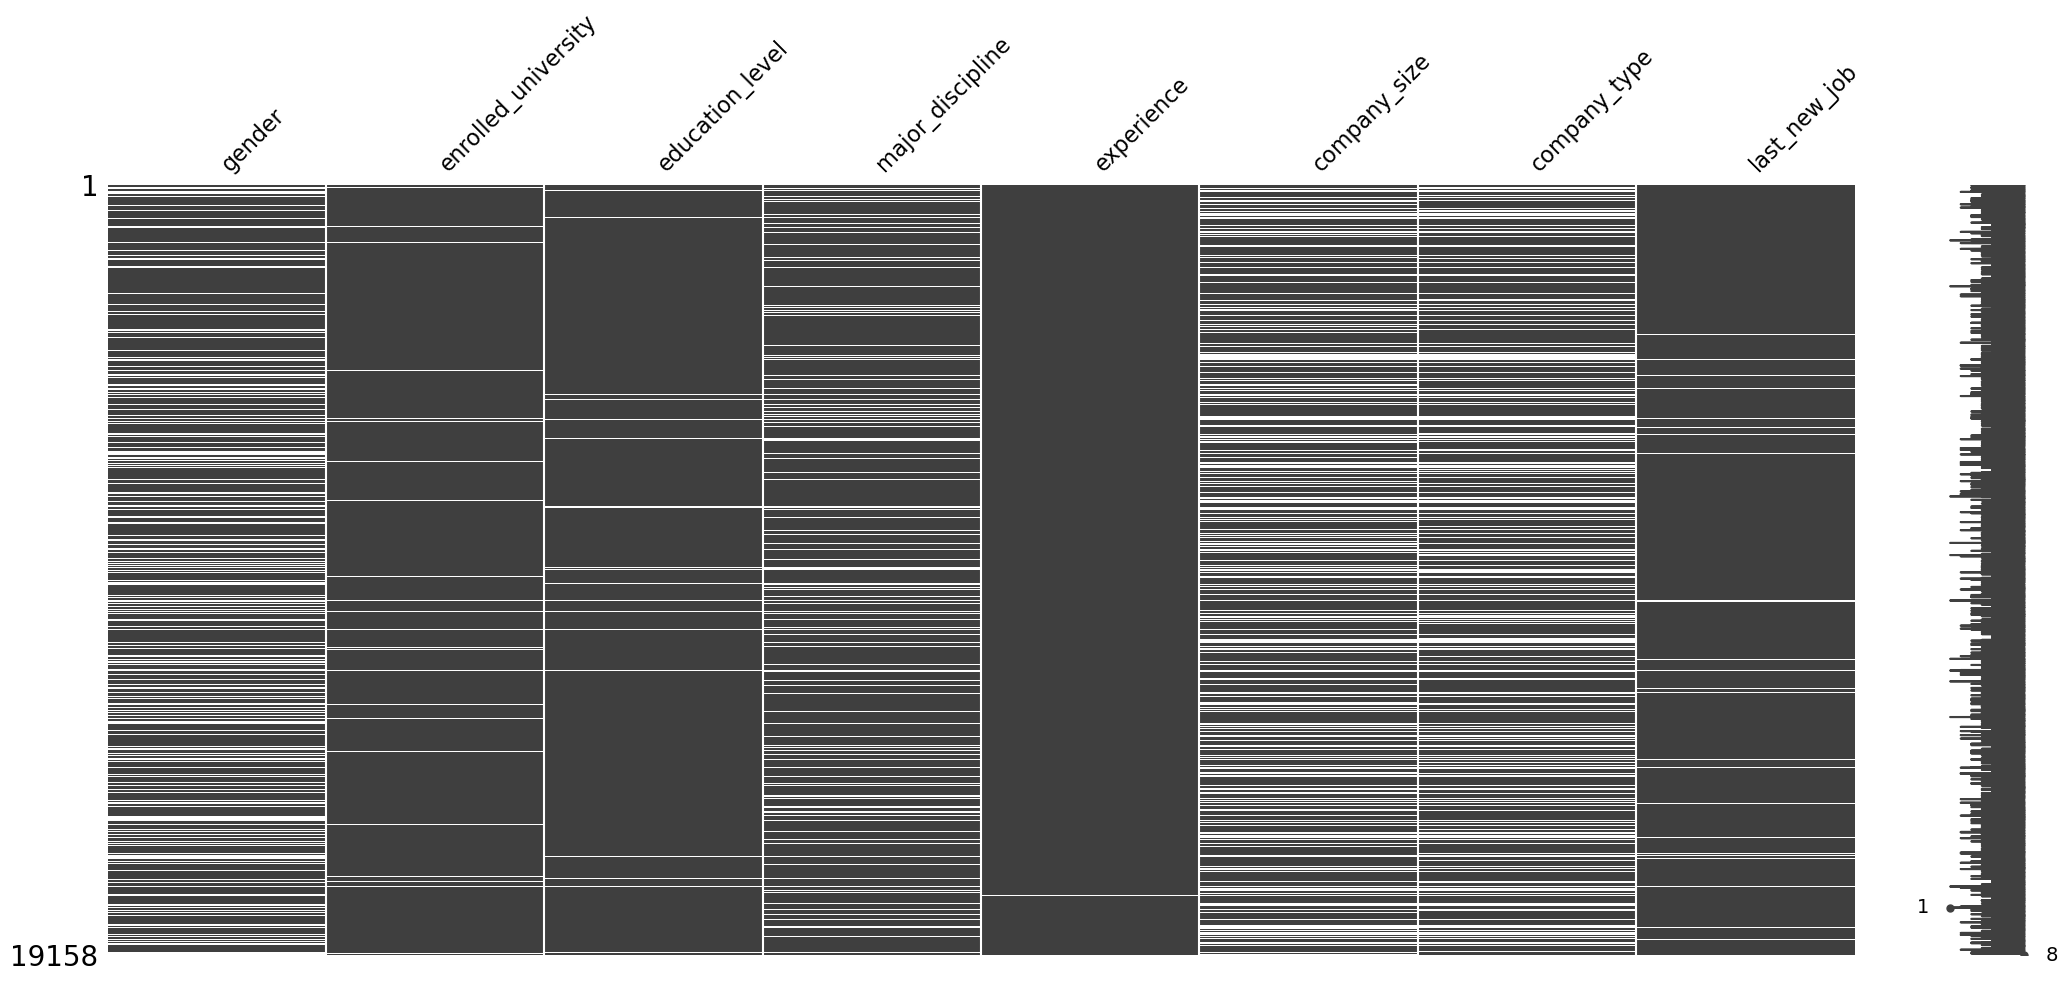

In [35]:
# Gera a visualização

# Dataframe
df_nan = pd.DataFrame(df.isna().sum())

# Plot - Mapa de Valores Ausentes
if df.isna().any(axis = None):
    missingno.matrix(df[df_nan[df_nan[0]>0].index])
    plt.show()

O mapa acima mostra onde estão os valores ausentes, mas olhar o gráfico não é suficiente para dizer se a ausência é aleatória.
Abaixo eu testo isso: se a ausência fosse completamente aleatória, a taxa de intenção de mudança seria parecida
entre os registros com e sem o valor preenchido.

In [36]:
# Testando se a ausência de cada variável está associada ao target
resultado = []
for col in df.columns[df.isna().any()]:
    ausente = df[col].isna()
    tabela = pd.crosstab(ausente, df['target'])
    chi2, p_valor, _, _ = chi2_contingency(tabela, correction = False)
    resultado.append({'variavel': col,
                      'qtd_ausentes': ausente.sum(),
                      'pct_ausentes': ausente.mean() * 100,
                      'taxa_target_ausente': df.loc[ausente, 'target'].mean() * 100,
                      'taxa_target_preenchido': df.loc[~ausente, 'target'].mean() * 100,
                      'v_cramer': np.sqrt(chi2 / tabela.values.sum()),
                      'p_valor': p_valor})

pd.DataFrame(resultado).set_index('variavel').sort_values('v_cramer', ascending = False).round(4)

,qtd_ausentes,pct_ausentes,taxa_target_ausente,taxa_target_preenchido,v_cramer,p_valor
variavel,,,,,,
company_size,5938,30.9949,40.5861,17.9047,0.2425,0.0000
company_type,6140,32.0493,38.8274,18.3822,0.2205,0.0000
gender,4508,23.5306,30.8119,23.1263,0.0754,0.0000
major_discipline,2813,14.6832,19.5165,25.8672,0.0520,0.0000
last_new_job,423,2.2080,36.4066,24.6757,0.0398,0.0000
enrolled_university,386,2.0148,31.8653,24.7922,0.0230,0.0015
experience,65,0.3393,35.3846,24.8992,0.0141,0.0511
education_level,460,2.4011,22.6087,24.9920,0.0084,0.2431


In [37]:
# Quem não informou company_type também deixou de informar company_size? E tem experiência relevante?
sem_company_type = df['company_type'].isna().map({True: 'company_type ausente', False: 'company_type preenchido'})

print(pd.crosstab(sem_company_type, df['company_size'].isna().map({True: 'company_size ausente', False: 'company_size preenchido'}), normalize = 'index').round(3) * 100)
print()
print(pd.crosstab(sem_company_type, df['relevent_experience'], normalize = 'index').round(3) * 100)

company_size             company_size ausente  company_size preenchido
company_type                                                          
company_type ausente                     87.3                     12.7
company_type preenchido                   4.4                     95.6

relevent_experience      Has relevent experience  No relevent experience
company_type                                                            
company_type ausente                        48.5                    51.5
company_type preenchido                     83.1                    16.9


**A ausência não é completamente aleatória.**

- Em `company_type` e `company_size` a diferença é grande: quem deixou o campo em branco declara intenção de mudança em cerca de 39% a 41% dos casos, contra cerca de 18% de quem preencheu.
- Os dois campos faltam juntos em cerca de 87% dos casos, e metade desses candidatos não tem experiência relevante (contra 17% entre os que informaram a empresa). A explicação mais provável é que são pessoas sem empregador atual, para quem a pergunta não se aplica. Isso é uma hipótese: o dataset não tem um campo que confirme.
- Em `gender`, `major_discipline`, `last_new_job` e `enrolled_university` a diferença existe e é estatisticamente significativa, mas a associação é fraca (V de Cramér abaixo de 0,1).
- Em `education_level` e `experience` não há evidência de associação ao nível de 5%.

Consequência para o tratamento: como a ausência carrega informação, não faz sentido imputar pela moda nem simplesmente
apagar as linhas. Nas variáveis categóricas o ausente será mantido como uma categoria própria.

In [38]:
# verificando duplicidade 
df['enrollee_id'].duplicated().sum()

0

### Identificando Dados Desbalanceados

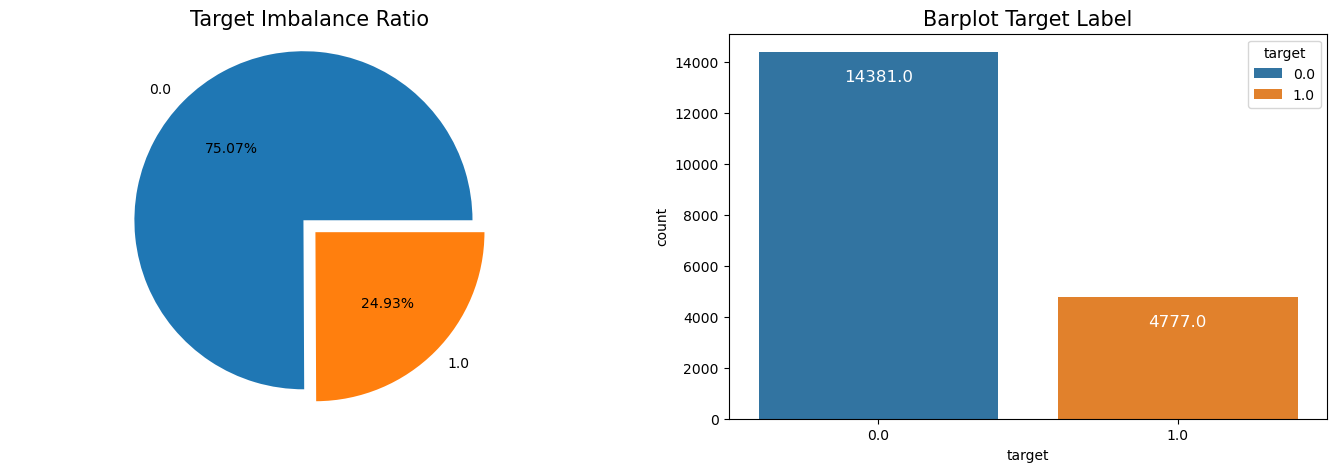

In [39]:
# Figura
plt.figure(figsize = (17,(100)/20))

plt.subplot(121)

plt.pie(round(df['target'].value_counts() / len(df) * 100, 2),
        labels = list(df['target'].value_counts().index),
        autopct = "%.2f%%",
        explode = (0,0.1))

plt.axis("equal")
plt.title("Target Imbalance Ratio", size = 15)

plt.subplot(122)
ax = sns.countplot(data = df, hue = 'target', x = 'target')
plt.title("Barplot Target Label", fontsize = 15)
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', 
                (p.get_x()+0.4, 
                 p.get_height()), 
                ha = 'center', 
                va = 'top', 
                color = 'white', 
                size = 12)

Os dados estão desbalanceados em relação à variável target.

## Limpeza e Processamento dos Dados

### Tratando os Valores Ausentes

In [40]:
df.columns

Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='object')

In [41]:
#criando uma lista com as colunas que serão utilizadas
colunas_manter = ['city_development_index', 
                  'experience', 
                  'enrolled_university', 
                  'relevent_experience', 
                  'education_level',
                  'company_type',
                  'major_discipline',
                  'target']

In [42]:
#novo df (uso .copy() para não alterar o df original nem depender de uma fatia dele)
new_df = df[colunas_manter].copy()

In [43]:
new_df.head()

,city_development_index,experience,enrolled_university,relevent_experience,education_level,company_type,major_discipline,target
0,0.920,>20,no_enrollment,Has relevent experience,Graduate,NaN,STEM,1.0
1,0.776,15,no_enrollment,No relevent experience,Graduate,Pvt Ltd,STEM,0.0
2,0.624,5,Full time course,No relevent experience,Graduate,NaN,STEM,0.0
3,0.789,<1,NaN,No relevent experience,Graduate,Pvt Ltd,Business Degree,1.0
4,0.767,>20,no_enrollment,Has relevent experience,Masters,Funded Startup,STEM,0.0


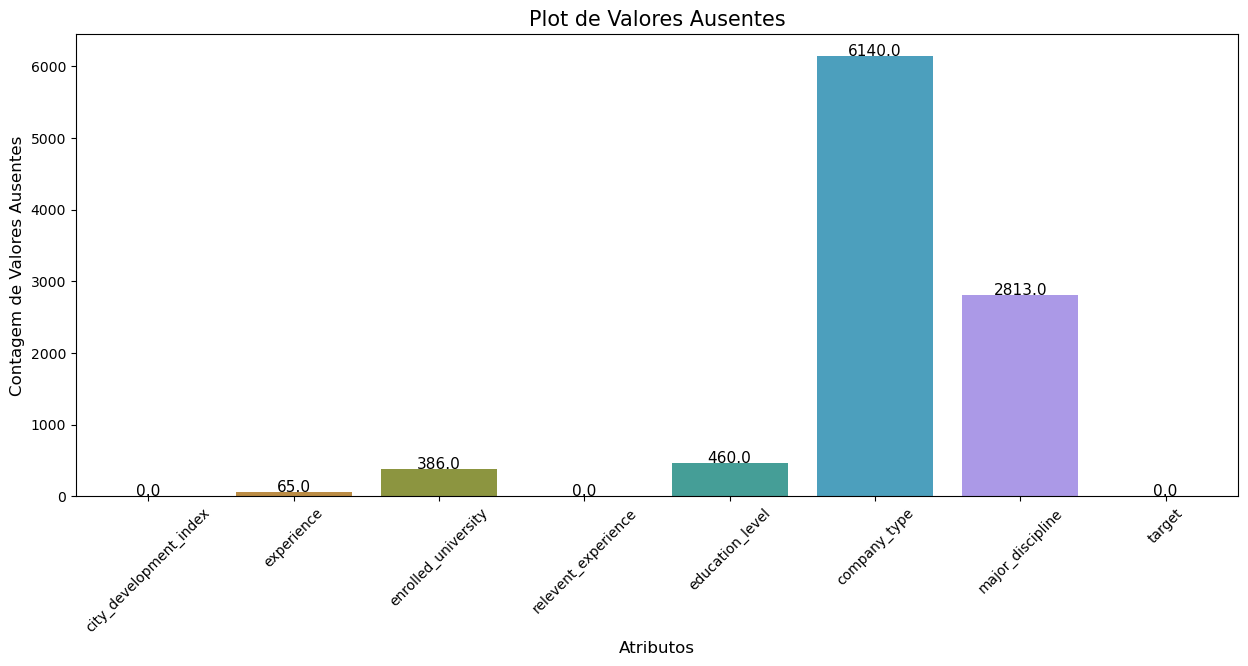

In [44]:
# Valores ausentes por coluna
null_df = new_df.isna().sum().reset_index()

# Figura
ax = plt.figure(figsize = (15,6))

# Barplot
ax = sns.barplot(x = null_df['index'], y = null_df[0], palette = 'husl')
plt.xlabel('Atributos', fontsize = 12)
plt.ylabel('Contagem de Valores Ausentes', fontsize = 12)
plt.xticks(rotation = 45)
plt.title("Plot de Valores Ausentes", fontsize = 15)

for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, (p.get_height())), ha = 'center', color = 'black', size = 11)

plt.show()

Visualizando o gráfico temos 5 variáveis que  possuem valores ausentes.

#### Variável major_discipline

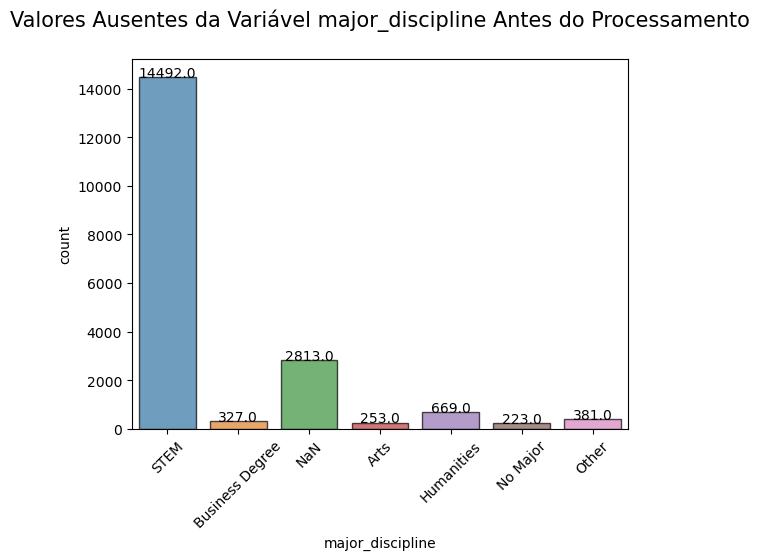

In [45]:
# Valores Ausentes da Variável major_discipline Antes do Processamento
sns.countplot(data = new_df.fillna('NaN'), x = 'major_discipline',hue = 'major_discipline', alpha = 0.7, edgecolor = 'black')
plt.xticks(rotation = 45)
bound = ax.get_xbound()
ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 10)
plt.title("Valores Ausentes da Variável major_discipline Antes do Processamento\n", fontsize = 15)
plt.show()

In [46]:
# Relação entre major_discipline x education_level
print('\nTotal de Valores Ausentes na Variável major_discipline:', new_df['major_discipline'].isna().sum())
print('\nProporção de Valores Ausentes na Variável education_level:')
new_df[new_df['major_discipline'].isna()]['education_level'].value_counts(dropna = False)


Total de Valores Ausentes na Variável major_discipline: 2813

Proporção de Valores Ausentes na Variável education_level:


education_level
High School       2017
NaN                460
Primary School     308
Graduate            22
Masters              6
Name: count, dtype: int64

Dentre os registros com valores ausentes, vemos a proporção na variável education_level.

Preencheremos os valores NA da variável `major_discipline` com `Non Degree`. Pois eles não possuem graduação

In [47]:
# Cria o índice
nan_index = (new_df[(new_df['major_discipline'].isna()) & ((new_df['education_level']=='High School') | (new_df['education_level'].isna()) | (new_df['education_level']=='Primary School'))]).index


In [48]:
len(nan_index)

2785

In [49]:
# Imputação do valor ausente
new_df.loc[nan_index, 'major_discipline'] = 'Non Degree'

In [50]:
print('Total de Valores Ausentes na Variável major_discipline:', new_df['major_discipline'].isna().sum())
new_df['major_discipline'].value_counts(dropna = False)

Total de Valores Ausentes na Variável major_discipline: 28


major_discipline
STEM               14492
Non Degree          2785
Humanities           669
Other                381
Business Degree      327
Arts                 253
No Major             223
NaN                   28
Name: count, dtype: int64

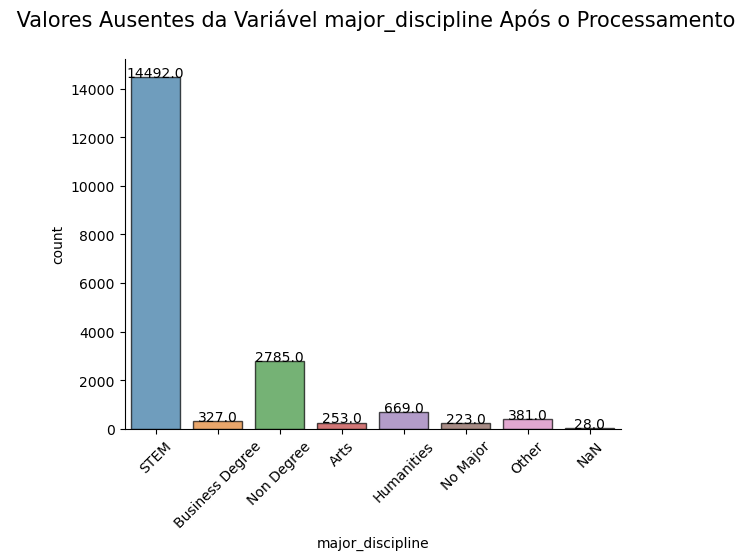

In [51]:
# Valores Ausentes da Variável major_discipline Após o Processamento
sns.countplot(data = new_df.fillna('NaN'), x = 'major_discipline', hue = 'major_discipline' , alpha = 0.7, edgecolor = 'black')
sns.despine()
plt.xticks(rotation=45)
bound=ax.get_xbound()
ax=plt.gca()
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 10)
plt.title(" Valores Ausentes da Variável major_discipline Após o Processamento\n", fontsize = 15)
plt.show()

In [52]:
# Para os valores ausentes restantes preenchemos com 'Other'
new_df.loc[new_df['major_discipline'].isna(), 'major_discipline'] = 'Other'

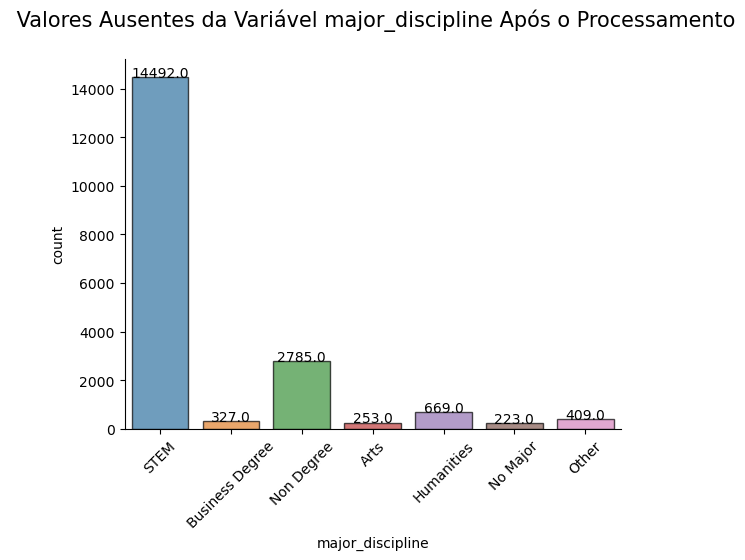

In [53]:
# Valores Ausentes da Variável major_discipline Após o Processamento
sns.countplot(data = new_df.fillna('NaN'), x = 'major_discipline', hue = 'major_discipline' , alpha = 0.7, edgecolor = 'black')
sns.despine()
plt.xticks(rotation=45)
bound=ax.get_xbound()
ax=plt.gca()
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 10)
plt.title(" Valores Ausentes da Variável major_discipline Após o Processamento\n", fontsize = 15)
plt.show()

In [54]:
#pelo gráfico acima vimos que agora não possue valor ausente
new_df.head()

,city_development_index,experience,enrolled_university,relevent_experience,education_level,company_type,major_discipline,target
0,0.920,>20,no_enrollment,Has relevent experience,Graduate,NaN,STEM,1.0
1,0.776,15,no_enrollment,No relevent experience,Graduate,Pvt Ltd,STEM,0.0
2,0.624,5,Full time course,No relevent experience,Graduate,NaN,STEM,0.0
3,0.789,<1,NaN,No relevent experience,Graduate,Pvt Ltd,Business Degree,1.0
4,0.767,>20,no_enrollment,Has relevent experience,Masters,Funded Startup,STEM,0.0


#### Variável enrolled_university

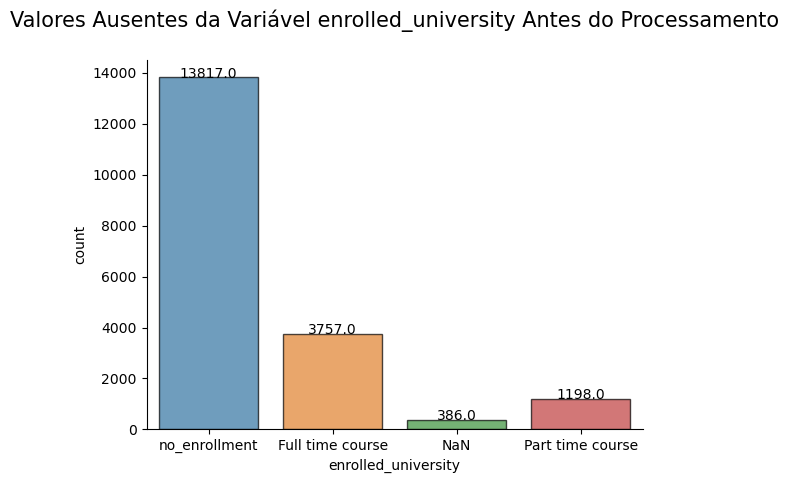

In [55]:
# Plot
sns.countplot(data = new_df.fillna('NaN'), x = 'enrolled_university', hue = 'enrolled_university', alpha = 0.7, edgecolor = 'black')
sns.despine()
plt.xticks()
bound=ax.get_xbound()
ax=plt.gca()
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 10)
plt.title("Valores Ausentes da Variável enrolled_university Antes do Processamento\n", fontsize = 15)
plt.show()

In [56]:
print('\nTotal de Valores Ausentes na Variável enrolled_university:', new_df['enrolled_university'].isna().sum())
print('\nProporção de Valores Ausentes na Variável education_level:')
new_df[new_df['enrolled_university'].isna()]['education_level'].value_counts(dropna = False)


Total de Valores Ausentes na Variável enrolled_university: 386

Proporção de Valores Ausentes na Variável education_level:


education_level
Graduate          171
NaN               100
Masters            53
High School        47
Primary School      9
Phd                 6
Name: count, dtype: int64

Candidatos com `Primary School` como `education_level` não estão qualificados para ingressar na universidade. Portanto, preencheremos os valores `NaN` de `enrolled_university` desses candidatos com `Primary Grad`.

In [57]:
# Prepara o índice
nan_index = (new_df[(new_df['enrolled_university'].isna()) & (new_df['education_level']=='Primary School')]).index

In [58]:
len(nan_index)

9

In [59]:
# Imputação de valores ausentes
new_df.loc[nan_index, 'enrolled_university'] = 'Primary Grad'

In [60]:
print('Total de Valores Ausentes:', new_df['enrolled_university'].isna().sum())
new_df[new_df['enrolled_university'].isna()]['education_level'].value_counts(dropna = False)

Total de Valores Ausentes: 377


education_level
Graduate       171
NaN            100
Masters         53
High School     47
Phd              6
Name: count, dtype: int64

In [61]:
#índice
nan_index = new_df[(new_df['enrolled_university'].isna())].index

In [62]:
# Como não há nenhum critério na documentação vou colocar como: 'Other' os outros valores ausentes
new_df.loc[nan_index, 'enrolled_university'] = 'Other'

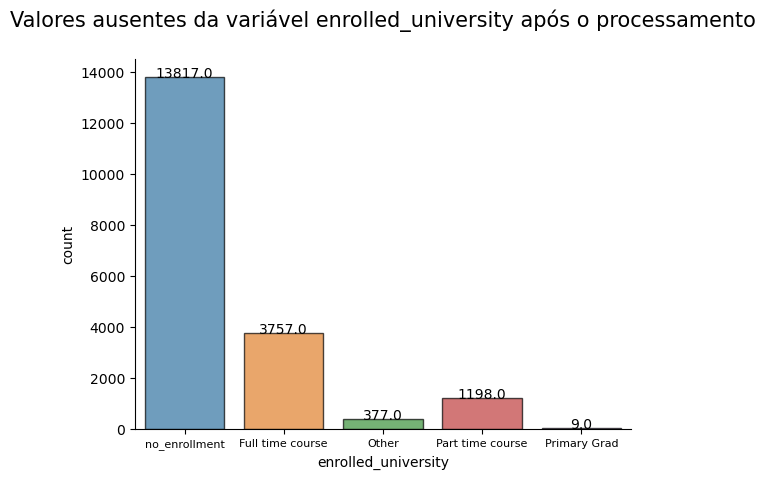

In [63]:
# Com o plot vou ver o gráfico com a nova nomenclatura 
sns.countplot(data = new_df.fillna('NaN'), x = 'enrolled_university',hue =  'enrolled_university',alpha = 0.7, edgecolor = 'black')
sns.despine()
plt.xticks(fontsize = 8)
bound=ax.get_xbound()
ax=plt.gca()
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 10)
plt.title("Valores ausentes da variável enrolled_university após o processamento\n", fontsize = 15)
plt.show()

In [64]:
#Vamos observar as vaiáveis a que possuem valores ausentes 
new_df.head()

,city_development_index,experience,enrolled_university,relevent_experience,education_level,company_type,major_discipline,target
0,0.920,>20,no_enrollment,Has relevent experience,Graduate,NaN,STEM,1.0
1,0.776,15,no_enrollment,No relevent experience,Graduate,Pvt Ltd,STEM,0.0
2,0.624,5,Full time course,No relevent experience,Graduate,NaN,STEM,0.0
3,0.789,<1,Other,No relevent experience,Graduate,Pvt Ltd,Business Degree,1.0
4,0.767,>20,no_enrollment,Has relevent experience,Masters,Funded Startup,STEM,0.0


#### Variável company_type

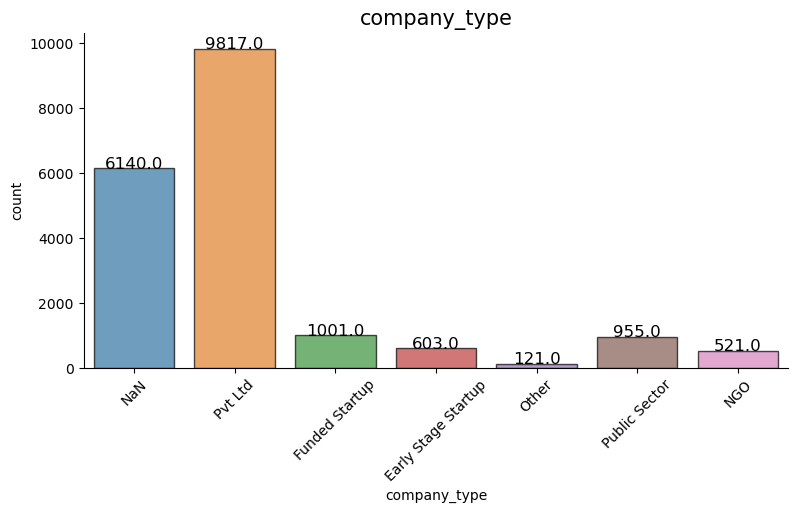

In [65]:
# Plotando para contar a quantidade de itens NaN
# Plot
plt.figure(figsize = (20, 20))
column_list = ['company_type']
A = 0
for i in column_list:
    A+=1
    plt.subplot(4,2,A)
    ax = sns.countplot(data = new_df.fillna('NaN'), x = i, hue = i, alpha = 0.7, edgecolor = 'black')
    sns.despine() 
    plt.title(i, fontsize = 15)
    for p in ax.patches:
        ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 12)
    if A >=0:
        plt.xticks(rotation = 45)

In [66]:
#contando elementos por categoria
new_df ['company_type'].value_counts(dropna = False)

company_type
Pvt Ltd                9817
NaN                    6140
Funded Startup         1001
Public Sector           955
Early Stage Startup     603
NGO                     521
Other                   121
Name: count, dtype: int64

São 6.140 ausentes (32% da base) e, como visto no teste de ausência, eles não são aleatórios: têm taxa de intenção de mudança bem maior que os demais.
Não vou imputar pela moda (`Pvt Ltd`), porque isso misturaria dois grupos com comportamentos diferentes. Vou preencher com `Other`.
**Limitação:** a categoria `Other` já existe com 121 respostas reais; depois da imputação ela passa a representar principalmente "não informado".

In [67]:
#criando o índice
nan_index = new_df[new_df['company_type'].isna()].index

In [68]:
#imputando other onde era NaN
new_df['company_type'] = new_df['company_type'].fillna('Other')

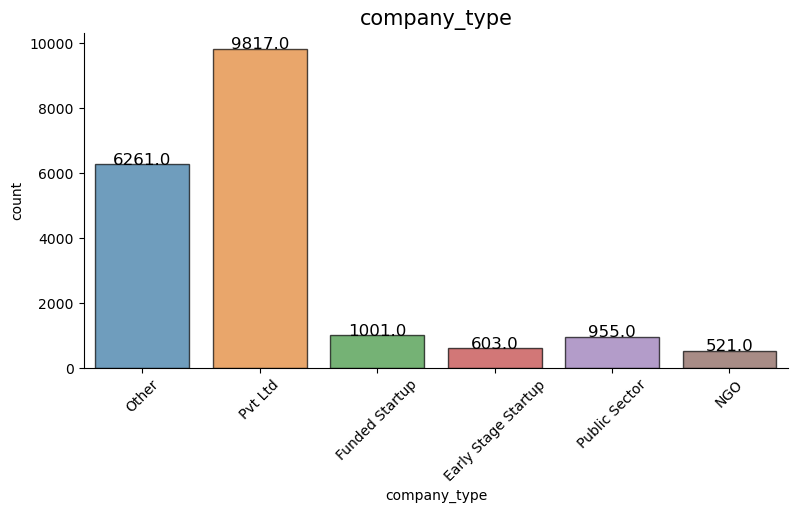

In [69]:
#plotando o gráfico com a alteração

# Plot
plt.figure(figsize = (20, 20))
column_list = ['company_type']
A = 0
for i in column_list:
    A+=1
    plt.subplot(4,2,A)
    ax = sns.countplot(data = new_df.fillna('NaN'), x = i, hue = i, alpha = 0.7, edgecolor = 'black')
    sns.despine() 
    plt.title(i, fontsize = 15)
    for p in ax.patches:
        ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 12)
    if A >=0:
        plt.xticks(rotation = 45)

In [70]:
#analisando outra categoria
new_df.head()

,city_development_index,experience,enrolled_university,relevent_experience,education_level,company_type,major_discipline,target
0,0.920,>20,no_enrollment,Has relevent experience,Graduate,Other,STEM,1.0
1,0.776,15,no_enrollment,No relevent experience,Graduate,Pvt Ltd,STEM,0.0
2,0.624,5,Full time course,No relevent experience,Graduate,Other,STEM,0.0
3,0.789,<1,Other,No relevent experience,Graduate,Pvt Ltd,Business Degree,1.0
4,0.767,>20,no_enrollment,Has relevent experience,Masters,Funded Startup,STEM,0.0


#### Variável education_level

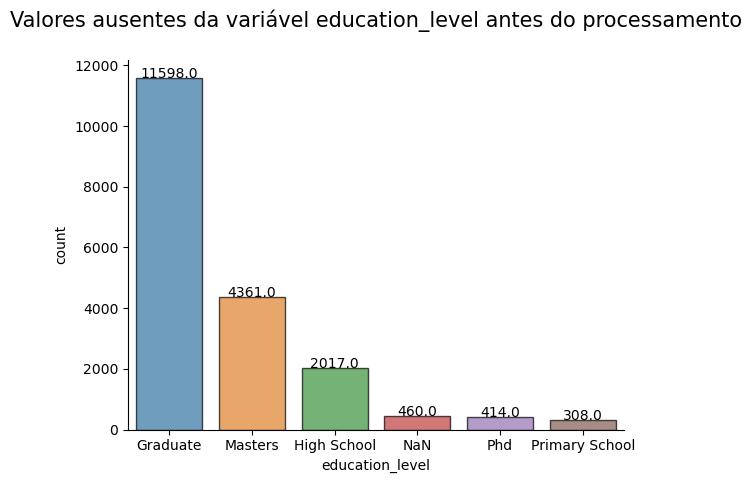

In [71]:
# Plot
sns.countplot(data = new_df.fillna('NaN'), x = 'education_level', hue = 'education_level', alpha = 0.7, edgecolor = 'black')
sns.despine()
plt.xticks()
bound=ax.get_xbound()
ax=plt.gca()
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 10)
plt.title("Valores ausentes da variável education_level antes do processamento\n", fontsize = 15)
plt.show()

São 460 ausentes (2,4%) e a ausência não mostrou associação significativa com o target.
Vou manter como categoria separada (`Other`, no sentido de "não informado") para não atribuir um nível de escolaridade que não sei qual é.

In [72]:
# Índice
nan_index = new_df[(new_df['education_level'].isna())].index

In [73]:
# Imputação dos valores NaN com 'Other'
new_df.loc[nan_index, 'education_level'] = 'Other'

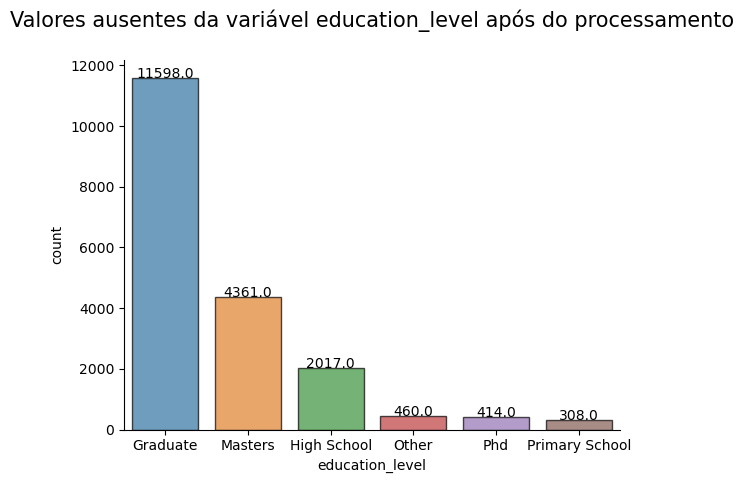

In [74]:
# Plot
sns.countplot(data = new_df.fillna('NaN'), x = 'education_level', hue = 'education_level' , alpha = 0.7, edgecolor = 'black')
sns.despine()
plt.xticks()
bound=ax.get_xbound()
ax=plt.gca()
for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, p.get_height()), ha = 'center', color = 'black', size = 10)
plt.title("Valores ausentes da variável education_level após do processamento\n", fontsize = 15)
plt.show()

In [75]:
new_df.head()

,city_development_index,experience,enrolled_university,relevent_experience,education_level,company_type,major_discipline,target
0,0.920,>20,no_enrollment,Has relevent experience,Graduate,Other,STEM,1.0
1,0.776,15,no_enrollment,No relevent experience,Graduate,Pvt Ltd,STEM,0.0
2,0.624,5,Full time course,No relevent experience,Graduate,Other,STEM,0.0
3,0.789,<1,Other,No relevent experience,Graduate,Pvt Ltd,Business Degree,1.0
4,0.767,>20,no_enrollment,Has relevent experience,Masters,Funded Startup,STEM,0.0


#### Variável exeperience

In [76]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city_development_index  19158 non-null  float64
 1   experience              19093 non-null  object 
 2   enrolled_university     19158 non-null  object 
 3   relevent_experience     19158 non-null  object 
 4   education_level         19158 non-null  object 
 5   company_type            19158 non-null  object 
 6   major_discipline        19158 non-null  object 
 7   target                  19158 non-null  float64
dtypes: float64(2), object(6)
memory usage: 1.2+ MB


In [77]:
new_df['experience'].value_counts(dropna = False)

experience
>20    3286
5      1430
4      1403
3      1354
6      1216
2      1127
7      1028
10      985
9       980
8       802
15      686
11      664
14      586
1       549
<1      522
16      508
12      494
13      399
17      342
19      304
18      280
20      148
NaN      65
Name: count, dtype: int64

In [78]:
# Percentual de valores ausentes
percent_missing = new_df.isnull().sum() / len(new_df) * 100
percent_missing

city_development_index    0.000000
experience                0.339284
enrolled_university       0.000000
relevent_experience       0.000000
education_level           0.000000
company_type              0.000000
major_discipline          0.000000
target                    0.000000
dtype: float64

In [79]:
# quantidade de valor ausente 
new_df['experience'].isnull().sum()

65

In [80]:
new_df.shape

(19158, 8)

In [81]:
# como a porcentagem de valor ausente é irrisório decidi dropar
new_df = new_df.dropna()

In [82]:
new_df.shape

(19093, 8)

In [83]:
# percentual dos itens ausentes depois do tratamento
percent_missing = new_df.isnull().sum() * 100 / len(new_df)
percent_missing

city_development_index    0.0
experience                0.0
enrolled_university       0.0
relevent_experience       0.0
education_level           0.0
company_type              0.0
major_discipline          0.0
target                    0.0
dtype: float64

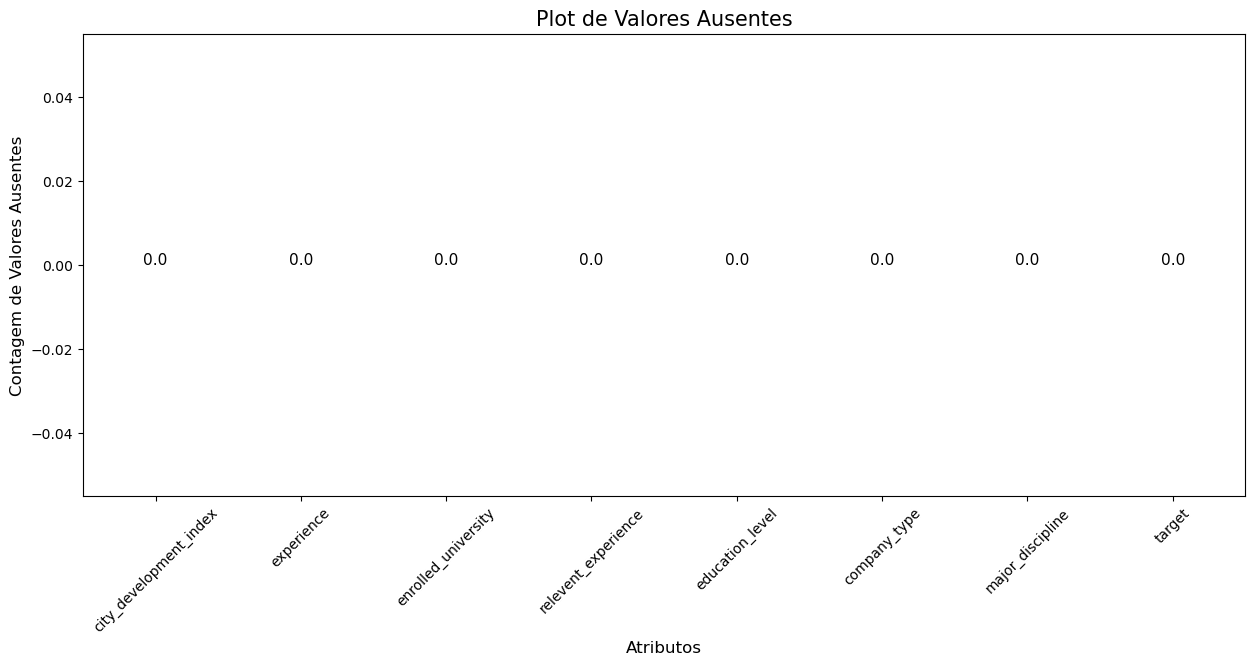

In [84]:
# plotando valores ausentes por coluna
null_df = new_df.isna().sum().reset_index()

# Figura
ax = plt.figure(figsize = (15,6))

# Barplot
ax = sns.barplot(x=null_df['index'], y=null_df[0], palette='husl')
plt.xlabel('Atributos', fontsize = 12)
plt.ylabel('Contagem de Valores Ausentes', fontsize = 12)
plt.xticks(rotation = 45)
plt.title("Plot de Valores Ausentes", fontsize = 15)

for p in ax.patches:
    ax.annotate(f'\n{p.get_height()}', (p.get_x()+0.4, (p.get_height())), ha = 'center', color = 'black', size = 11)

plt.show()

### Ajustes finais

In [85]:
# Ajustando os dados, como os itens começam com letra maiuscula então alterei para padronizar
new_df['enrolled_university'] = new_df['enrolled_university'].replace('no_enrollment', 'No enrollment')

In [86]:
new_df.head()

,city_development_index,experience,enrolled_university,relevent_experience,education_level,company_type,major_discipline,target
0,0.920,>20,No enrollment,Has relevent experience,Graduate,Other,STEM,1.0
1,0.776,15,No enrollment,No relevent experience,Graduate,Pvt Ltd,STEM,0.0
2,0.624,5,Full time course,No relevent experience,Graduate,Other,STEM,0.0
3,0.789,<1,Other,No relevent experience,Graduate,Pvt Ltd,Business Degree,1.0
4,0.767,>20,No enrollment,Has relevent experience,Masters,Funded Startup,STEM,0.0


## Síntese das decisões de tratamento

Resumo de tudo o que foi decidido na limpeza, com a justificativa e o risco de cada escolha.

| Variável | Ausentes | Decisão | Justificativa | Risco / limitação |
|---|---|---|---|---|
| `major_discipline` | 2.813 (14,7%) | 2.785 viram `Non Degree`; os 28 restantes viram `Other` | 2.785 desses candidatos têm `education_level` igual a `High School`, `Primary School` ou ausente, ou seja, não há graduação registrada, então não há especialização a informar. Os 28 restantes são graduados/mestres sem área informada. | Para os 460 com `education_level` também ausente, "sem graduação" é uma suposição que não consigo verificar. |
| `enrolled_university` | 386 (2,0%) | 9 viram `Primary Grad`; 377 viram `Other` | Quem tem só ensino primário não pode estar matriculado em universidade. Para os demais não há critério na documentação. | `Other` aqui significa "não informado", não um tipo de matrícula. |
| `company_type` | 6.140 (32,0%) | Preenchido com `Other` | A ausência não é aleatória (ver teste na seção de valores ausentes): ela aparece junto com `company_size` ausente e com falta de experiência relevante, o que sugere candidatos sem empregador atual. Imputar pela moda (`Pvt Ltd`) jogaria 6.140 pessoas com taxa de intenção de ~39% dentro de uma categoria com taxa de ~18%, distorcendo as duas. | A categoria `Other` já existia com 121 respostas reais. Depois da imputação ela é ~98% "não informado". Deve ser lida assim no dashboard. |
| `education_level` | 460 (2,4%) | Preenchido com `Other` | Poucos registros e ausência sem associação significativa com o target; manter como categoria separada evita inventar um nível de escolaridade. | `Other` significa "não informado". |
| `experience` | 65 (0,3%) | Linhas removidas | Volume irrisório; a variável é ordinal e não há critério defensável para imputar. | A taxa do target nesses 65 é mais alta que a média, mas o efeito na base é desprezível (verificado abaixo). |

**Colunas descartadas:** `enrollee_id` e `city` (identificadores; `city` já está representada pelo `city_development_index`),
`gender` (IV próximo de zero e 23,5% de ausentes), `company_size` (31,0% de ausentes, faltando quase sempre junto com `company_type`),
`last_new_job` e `training_hours` (correlação próxima de zero com o target).

**Por que categoria própria em vez de moda/mediana:** em todas as variáveis categóricas preferi marcar o ausente
como uma categoria separada. Assim as taxas das categorias originais não são alteradas pela imputação e o
próprio fato de o dado estar ausente continua visível na análise.

**Observação sobre o IV de `company_type`:** o Information Value calculado antes (0,018) ignora os ausentes.
Tratando o ausente como categoria, o IV sobe para cerca de 0,26. Foi por isso que mantive a variável,
mesmo ela aparecendo como fraca no gráfico de IV.

## Verificação de robustez

As conclusões dependem das decisões de tratamento? Fiz quatro verificações.

In [87]:
# Função auxiliar: V de Cramér (força da associação entre duas variáveis categóricas, de 0 a 1)
def cramers_v(x, y):
    tabela = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabela, correction = False)[0]
    return np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))

#### Verificação 1: a força da associação muda conforme o tratamento dos ausentes?

In [88]:
colunas_imputadas = ['enrolled_university', 'education_level', 'company_type', 'major_discipline']

linhas = []
for col in colunas_imputadas:
    sem_ausentes = df.dropna(subset = [col])
    linhas.append({'variavel': col,
                   'pct_ausente': df[col].isna().mean() * 100,
                   'v_excluindo_ausentes': cramers_v(sem_ausentes[col], sem_ausentes['target']),
                   'v_ausente_como_categoria': cramers_v(df[col].fillna('Ausente'), df['target']),
                   'v_dataset_tratado': cramers_v(new_df[col], new_df['target'])})

pd.DataFrame(linhas).set_index('variavel').round(3)

,pct_ausente,v_excluindo_ausentes,v_ausente_como_categoria,v_dataset_tratado
variavel,,,,
enrolled_university,2.015,0.156,0.156,0.155
education_level,2.401,0.094,0.093,0.093
company_type,32.049,0.052,0.224,0.222
major_discipline,14.683,0.027,0.058,0.059


#### Verificação 2: a imputação alterou a taxa das categorias originais?

Comparo a taxa de intenção de mudança (%) de cada categoria na base bruta e na base tratada.
Categorias que só existem depois do tratamento aparecem sem valor na coluna da base bruta.

In [89]:
bruto = df.copy()
bruto['enrolled_university'] = bruto['enrolled_university'].replace('no_enrollment', 'No enrollment')

partes = []
for col in colunas_imputadas:
    antes = bruto.groupby(col)['target'].agg(taxa_bruto = 'mean', n_bruto = 'size')
    depois = new_df.groupby(col)['target'].agg(taxa_tratado = 'mean', n_tratado = 'size')
    comp = antes.join(depois, how = 'outer').rename_axis('categoria').reset_index()
    comp.insert(0, 'variavel', col)
    partes.append(comp)

comparacao = pd.concat(partes, ignore_index = True)
comparacao[['taxa_bruto', 'taxa_tratado']] = comparacao[['taxa_bruto', 'taxa_tratado']] * 100
comparacao['diferenca_pp'] = comparacao['taxa_tratado'] - comparacao['taxa_bruto']
comparacao.round(2)

,variavel,categoria,taxa_bruto,n_bruto,taxa_tratado,n_tratado,diferenca_pp
0,enrolled_university,Full time course,38.09,3757.0,38.03,3737,-0.06
1,enrolled_university,No enrollment,21.14,13817.0,21.12,13778,-0.02
2,enrolled_university,Other,NaN,NaN,32.26,372,NaN
3,enrolled_university,Part time course,25.21,1198.0,25.23,1197,0.02
4,enrolled_university,Primary Grad,NaN,NaN,11.11,9,NaN
5,education_level,Graduate,27.98,11598.0,27.93,11566,-0.05
6,education_level,High School,19.53,2017.0,19.57,2013,0.04
7,education_level,Masters,21.44,4361.0,21.42,4346,-0.02
8,education_level,Other,NaN,NaN,22.44,450,NaN
9,education_level,Phd,14.01,414.0,14.11,411,0.10


#### Verificação 3: as principais associações se mantêm só com registros completos?

Refaço as três associações mais fortes usando apenas candidatos sem nenhum valor ausente nas variáveis mantidas
(análise de casos completos) e comparo com a base inteira.

In [90]:
variaveis = [c for c in colunas_manter if c != 'target']

def com_faixa_cdi(base):
    base = base.copy()
    base['faixa_cdi'] = pd.cut(base['city_development_index'],
                               bins = [0, 0.6, 0.85, 1.01],
                               right = False,
                               labels = ['Baixo (< 0,60)', 'Medio (0,60 a 0,85)', 'Alto (>= 0,85)'])
    return base

base_total = com_faixa_cdi(df)
casos_completos = com_faixa_cdi(df.dropna(subset = variaveis))

print('Base total      :', len(base_total), 'registros | taxa do target:', round(base_total['target'].mean() * 100, 1), '%')
print('Casos completos :', len(casos_completos), 'registros | taxa do target:', round(casos_completos['target'].mean() * 100, 1), '%')

partes = []
for col in ['faixa_cdi', 'relevent_experience', 'enrolled_university']:
    total = base_total.groupby(col, observed = True)['target'].agg(taxa_total = 'mean', n_total = 'size')
    completos = casos_completos.groupby(col, observed = True)['target'].agg(taxa_completos = 'mean', n_completos = 'size')
    comp = total.join(completos).rename_axis('categoria').reset_index()
    comp.insert(0, 'variavel', col)
    partes.append(comp)

sensibilidade = pd.concat(partes, ignore_index = True)
sensibilidade[['taxa_total', 'taxa_completos']] = sensibilidade[['taxa_total', 'taxa_completos']] * 100
sensibilidade.round(1)

Base total      : 19158 registros | taxa do target: 24.9 %
Casos completos : 11708 registros | taxa do target: 18.7 %


,variavel,categoria,taxa_total,n_total,taxa_completos,n_completos
0,faixa_cdi,"Baixo (< 0,60)",57.9,725,57.1,373
1,faixa_cdi,"Medio (0,60 a 0,85)",38.6,6228,35.4,3611
2,faixa_cdi,"Alto (>= 0,85)",16.0,12205,9.0,7724
3,relevent_experience,Has relevent experience,21.5,13792,17.7,9967
4,relevent_experience,No relevent experience,33.8,5366,24.2,1741
5,enrolled_university,Full time course,38.1,3757,30.9,1424
6,enrolled_university,Part time course,25.2,1198,17.7,724
7,enrolled_university,no_enrollment,21.1,13817,16.9,9560


#### Verificação 4: remover os 65 registros sem `experience` mudou a base?

In [91]:
sem_experiencia = df['experience'].isna()
print('Taxa do target antes da remoção :', round(df['target'].mean() * 100, 2), '%')
print('Taxa do target depois da remoção:', round(new_df['target'].mean() * 100, 2), '%')
print('Taxa do target nos removidos    :', round(df.loc[sem_experiencia, 'target'].mean() * 100, 1), '% em', sem_experiencia.sum(), 'registros')

Taxa do target antes da remoção : 24.93 %
Taxa do target depois da remoção: 24.9 %
Taxa do target nos removidos    : 35.4 % em 65 registros


#### O que as verificações mostram

- **Verificação 1:** para `enrolled_university` e `education_level` a força da associação é praticamente a mesma nos três cenários; a conclusão não depende da imputação. Para `company_type` ela depende totalmente: excluindo os ausentes a associação é fraca (V ≈ 0,05), e tratando o ausente como categoria ela sobe para V ≈ 0,22. Ou seja, o sinal dessa variável vem de o campo estar ou não preenchido, e não do tipo de empresa.
- **Verificação 2:** as categorias originais mantêm a mesma taxa antes e depois do tratamento (diferenças de décimos de ponto percentual, causadas apenas pela remoção dos 65 registros). A exceção é `company_type = Other`, que sai de ~24% (121 respostas reais) para ~39% depois de absorver os não informados.
- **Verificação 3:** os casos completos têm taxa geral menor (18,7% contra 24,9%), porque quem tem dados faltando declara intenção de mudança com mais frequência. Mesmo assim, a **direção** das três associações se mantém: a taxa cai conforme o CDI sobe, é maior em quem não tem experiência relevante e é maior em matriculados em tempo integral. O **tamanho** das diferenças muda, então os percentuais devem ser lidos como descritivos desta base, não como estimativas precisas.
- **Verificação 4:** a remoção dos 65 registros altera a taxa geral em menos de 0,1 ponto percentual.

**Conclusão:** as associações com CDI, experiência relevante e matrícula universitária são robustas quanto à direção.
A leitura de `company_type` só é válida se a categoria `Other` for entendida como "não informado".

## Relatório final:

**O que foi analisado:** a intenção *declarada* de buscar um novo emprego (`target = 1`) entre 19.158 candidatos
inscritos no treinamento. Cerca de 24,9% declararam essa intenção. Não se trata de turnover efetivo.

**Variáveis mais associadas à intenção de mudança** (taxas calculadas na base bruta de treino):

- **Índice de desenvolvimento da cidade (CDI):** é a associação mais forte. A intenção aparece em cerca de 58% dos candidatos de cidades com CDI abaixo de 0,60, contra cerca de 16% nas cidades com CDI a partir de 0,85.
- **Tempo de experiência profissional:** cerca de 38% entre quem tem até 2 anos, contra cerca de 15% entre quem tem mais de 20 anos.
- **Matrícula em curso universitário:** cerca de 38% entre matriculados em tempo integral, contra cerca de 21% entre não matriculados.
- **Experiência relevante:** cerca de 34% entre quem não tem, contra cerca de 21% entre quem tem.
- **Nível educacional:** a taxa é maior entre graduados (cerca de 28%) e menor entre doutores (cerca de 14%); a relação não é linear.
- **Tipo de empresa:** o principal sinal não está no tipo em si, e sim em o campo **não ter sido informado** (cerca de 39% contra 18% quando informado).
- **Especialização na graduação:** associação fraca.

**Variáveis com pouca ou nenhuma associação com o target nesta análise:**

- O ID do candidato e o código da cidade (identificadores).
- O gênero.
- O tempo desde o último emprego (`last_new_job`).
- O total de horas de treinamento.
- O tamanho da empresa foi descartado por ter 31% de ausentes e carregar a mesma informação de `company_type` (os dois campos costumam faltar juntos).

**Limitações:**

- **Associação não é causalidade.** Os dados são observacionais e não controlei variáveis de confusão. Por exemplo, CDI, experiência e matrícula universitária se relacionam entre si; não é possível isolar o efeito de cada uma com esta análise.
- **Intenção não é comportamento.** O `target` é uma declaração feita no momento do treinamento. Não sabemos quem de fato trocou de emprego.
- **Ausência informativa.** A falta de `company_type` não é aleatória e a categoria `Other` dessa variável mistura 121 respostas reais com 6.140 não informados (ver síntese do tratamento).
- **Base desbalanceada** (cerca de 75% / 25%) e algumas categorias com poucos registros, cujas taxas são instáveis.
- As taxas são descritivas, variável a variável; não foi ajustado um modelo.

**Recomendações do Analista de Dados**:

- O RH pode melhorar a coleta de dados, principalmente dos campos sobre a empresa atual, tornando explícita a opção "não trabalho atualmente". Isso eliminaria a principal fonte de ausentes.

- Os perfis em que a intenção de mudança é mais frequente (cidades com CDI mais baixo, menos experiência, sem experiência relevante, matriculados em tempo integral) podem ser usados como **hipótese de triagem**, a ser validada com dados de contratação efetiva. Eles descrevem onde a intenção é mais comum, não o que a provoca.

- As horas de treinamento têm correlação próxima de zero com o target. Os dados não permitem concluir qual seria a duração ideal do treinamento.

In [92]:
# Exportando o dataset tratado para CSV (para uso em dashboard/BI)
caminho_saida = 'dataset/processed/hr_analytics_tratado.csv'
new_df.to_csv(caminho_saida, index=False)
print('Arquivo exportado:', caminho_saida)
print('Linhas:', new_df.shape[0], '| Colunas:', new_df.shape[1])

Arquivo exportado: dataset/processed/hr_analytics_tratado.csv
Linhas: 19093 | Colunas: 8


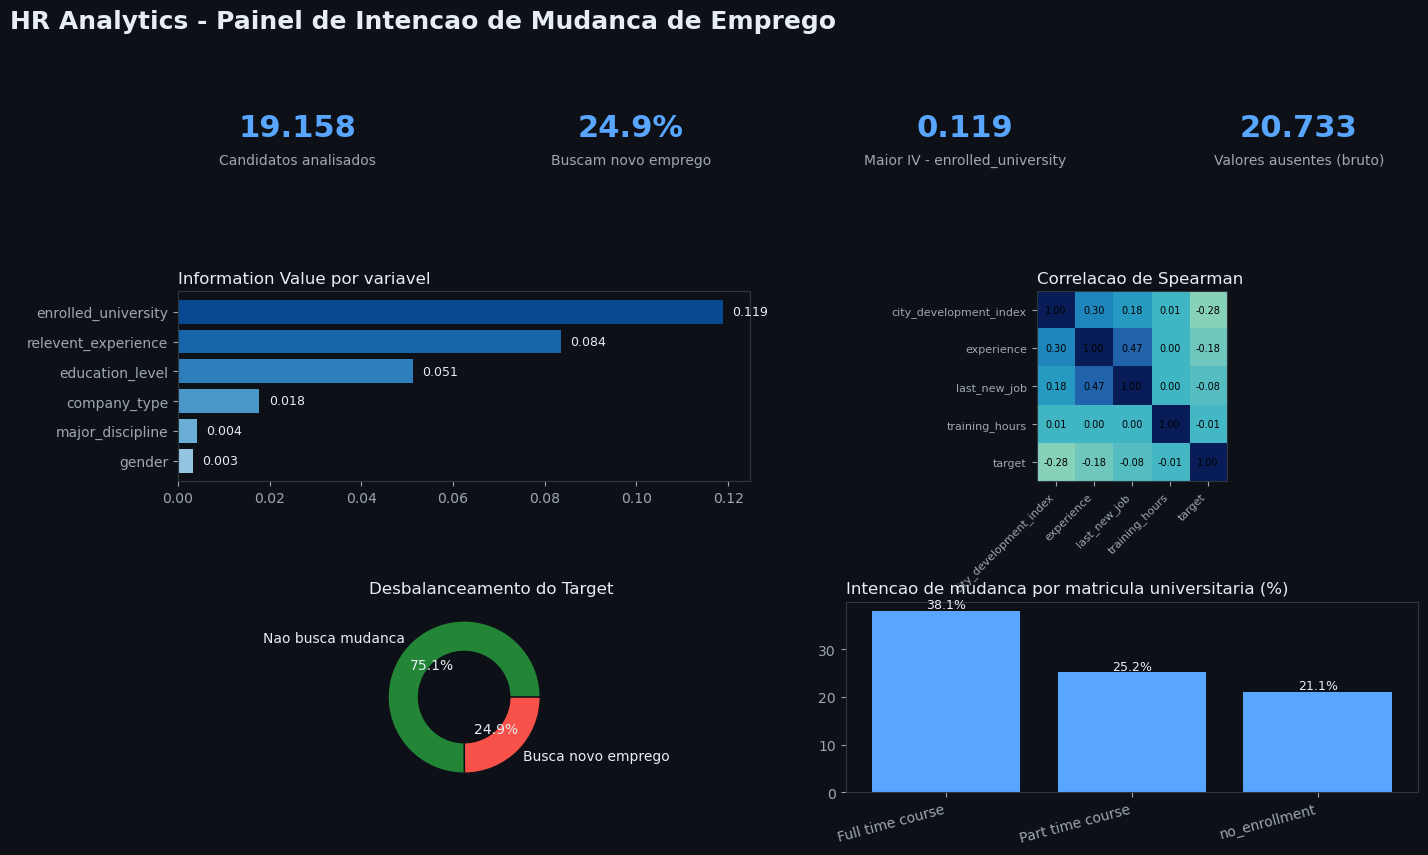

Dashboard salvo como dashboard_hr_analytics.png


In [93]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
columns_cat = list(df.drop(columns=['target', 'enrollee_id', 'city', 'city_development_index', 'training_hours', 'experience', 'last_new_job', 'company_size']).columns)
crosstabs = [pd.crosstab(df[c], df['target'], normalize='columns') for c in columns_cat]
iv_values = [np.sum(np.log(ct[1] / ct[0]) * (ct[1] - ct[0])) for ct in crosstabs]
df_iv = pd.DataFrame({'Feature': columns_cat, 'IV': iv_values}).set_index('Feature').sort_values('IV')
df_num = df.copy()
df_num['experience'] = df_num['experience'].replace({'<1': 1, '>20': 21}).astype(float)
df_num['last_new_job'] = df_num['last_new_job'].replace({'never': 0, '>4': 5}).astype(float)
corr = df_num.drop(columns=['enrollee_id']).corr(method='spearman', numeric_only=True)
taxa_uni = df.groupby('enrolled_university')['target'].mean().sort_values(ascending=False) * 100
total_candidatos = len(df)
pct_saida = df['target'].mean() * 100
iv_top_nome = df_iv['IV'].idxmax()
iv_top_valor = df_iv['IV'].max()
total_ausentes = int(df.isna().sum().sum())
plt.rcParams.update({'figure.facecolor': '#0d1117', 'axes.facecolor': '#0d1117', 'savefig.facecolor': '#0d1117', 'text.color': '#e6edf3', 'axes.labelcolor': '#e6edf3', 'xtick.color': '#9da7b3', 'ytick.color': '#9da7b3', 'axes.edgecolor': '#30363d', 'font.size': 10})
fig = plt.figure(figsize=(16, 9))
gs = gridspec.GridSpec(3, 4, figure=fig, height_ratios=[0.6, 1.6, 1.6], hspace=0.8, wspace=0.4)
fig.suptitle('HR Analytics - Painel de Intencao de Mudanca de Emprego', fontsize=18, fontweight='bold', color='#e6edf3', x=0.02, ha='left')
ax_k1 = fig.add_subplot(gs[0, 0])
ax_k1.axis('off')
ax_k1.text(0.5, 0.6, f"{total_candidatos:,}".replace(',', '.'), ha='center', va='center', fontsize=22, fontweight='bold', color='#58a6ff')
ax_k1.text(0.5, 0.15, 'Candidatos analisados', ha='center', va='center', fontsize=10, color='#9da7b3')
ax_k2 = fig.add_subplot(gs[0, 1])
ax_k2.axis('off')
ax_k2.text(0.5, 0.6, f"{pct_saida:.1f}%", ha='center', va='center', fontsize=22, fontweight='bold', color='#58a6ff')
ax_k2.text(0.5, 0.15, 'Buscam novo emprego', ha='center', va='center', fontsize=10, color='#9da7b3')
ax_k3 = fig.add_subplot(gs[0, 2])
ax_k3.axis('off')
ax_k3.text(0.5, 0.6, f"{iv_top_valor:.3f}", ha='center', va='center', fontsize=22, fontweight='bold', color='#58a6ff')
ax_k3.text(0.5, 0.15, f"Maior IV - {iv_top_nome}", ha='center', va='center', fontsize=10, color='#9da7b3')
ax_k4 = fig.add_subplot(gs[0, 3])
ax_k4.axis('off')
ax_k4.text(0.5, 0.6, f"{total_ausentes:,}".replace(',', '.'), ha='center', va='center', fontsize=22, fontweight='bold', color='#58a6ff')
ax_k4.text(0.5, 0.15, 'Valores ausentes (bruto)', ha='center', va='center', fontsize=10, color='#9da7b3')
ax1 = fig.add_subplot(gs[1, 0:2])
colors_iv = plt.cm.Blues(np.linspace(0.4, 0.9, len(df_iv)))
ax1.barh(df_iv.index, df_iv['IV'], color=colors_iv)
ax1.set_title('Information Value por variavel', fontsize=12, loc='left', color='#e6edf3')
iv_labels = [ax1.text(df_iv['IV'].iloc[i] + 0.002, i, f"{df_iv['IV'].iloc[i]:.3f}", va='center', fontsize=9, color='#e6edf3') for i in range(len(df_iv))]
ax2 = fig.add_subplot(gs[1, 2:4])
im = ax2.imshow(corr, cmap='YlGnBu', vmin=-1, vmax=1)
ax2.set_xticks(range(len(corr.columns)))
ax2.set_xticklabels(corr.columns, rotation=45, ha='right', fontsize=8)
ax2.set_yticks(range(len(corr.columns)))
ax2.set_yticklabels(corr.columns, fontsize=8)
corr_labels = [ax2.text(b, a, f"{corr.values[a, b]:.2f}", ha='center', va='center', fontsize=7, color='black') for a in range(len(corr.columns)) for b in range(len(corr.columns))]
ax2.set_title('Correlacao de Spearman', fontsize=12, loc='left', color='#e6edf3')
ax3 = fig.add_subplot(gs[2, 0:2])
vals = df['target'].value_counts(normalize=True) * 100
ax3.pie(vals, labels=['Nao busca mudanca', 'Busca novo emprego'], autopct='%.1f%%', colors=['#238636', '#f85149'], wedgeprops=dict(width=0.4, edgecolor='#0d1117'), textprops={'color': '#e6edf3'})
ax3.set_title('Desbalanceamento do Target', fontsize=12, loc='left', color='#e6edf3')
ax4 = fig.add_subplot(gs[2, 2:4])
ax4.bar(taxa_uni.index, taxa_uni.values, color='#58a6ff')
ax4.set_title('Intencao de mudanca por matricula universitaria (%)', fontsize=12, loc='left', color='#e6edf3')
ax4.set_xticklabels(taxa_uni.index, rotation=15, ha='right')
taxa_labels = [ax4.text(i, taxa_uni.values[i] + 0.5, f"{taxa_uni.values[i]:.1f}%", ha='center', fontsize=9, color='#e6edf3') for i in range(len(taxa_uni))]
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('dashboard_hr_analytics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Dashboard salvo como dashboard_hr_analytics.png')
